# Atividade 4: Estudo de caso, triagem de COVID-19 em radiografias de tórax

**Aluno:** Anderson Corrêa

**Objetivo:** um projeto de triagem de COVID-19 em radiografias chegou a 93% de acurácia no treino e 61% na validação. Este notebook reproduz esse projeto, mostra o que ele não reportou, treina uma GAN condicional em duas versões, com três seeds cada, verifica se as imagens geradas são cópias e mede se imagens sintéticas de COVID-19 aumentam a revocação (recall) da classe.

**Requisitos de execução**

- Ambiente: Google Colab com GPU T4
- Memória de GPU: cerca de 0,7 GB (medido na T4)
- Memória RAM: cerca de 2,2 GB (processo principal, medido na T4)
- Disco: 3 GB livres
- Tempo estimado: cerca de 23 minutos (medido na T4, sem contar a inicialização da máquina; o download de 0,8 GB pode variar)

**Como executar:** menu *Ambiente de execução*, *Executar tudo*. O notebook baixa os dados sozinho e não precisa de login.

## Código de apoio

As seis células abaixo definem as funções usadas no restante do notebook: execução, dados, laço de treino, radiografias, GAN e gráficos.

In [ ]:
"""Run setup and saving shared by the notebooks.

A run seeds the random generators, keeps its figures in one folder and ends
by writing its metrics and packing everything into one archive. The archive
layout is the contract with the script that collects the outputs of a Colab
run: ``metrics.json`` at the top level and the PNG files under ``figures/``.
"""

import json
import random
import sys
from contextlib import contextmanager
from dataclasses import dataclass
from pathlib import Path
from resource import RUSAGE_SELF, getrusage
from time import monotonic
from zipfile import ZIP_DEFLATED, ZipFile

import numpy as np
import torch

BYTES_PER_MEGABYTE = 1e6


class Stopwatch:
    """Measures how long the named steps of a run take.

    ``seconds`` maps every finished step to its duration, in the order the
    steps ran, ready to be saved with the metrics. Each step is also printed
    when it ends, so the cost of a notebook is visible while it runs.
    """

    def __init__(self) -> None:
        """Starts with no step measured."""
        self.seconds = {}

    @contextmanager
    def measure(self, name: str):
        """Times the body of a ``with`` block and records it under ``name``.

        A block that raises is not recorded.
        """
        started_at = monotonic()
        yield
        self.seconds[name] = round(monotonic() - started_at, 1)
        print(f"{name}: {self.seconds[name]} s")


@dataclass(frozen=True)
class Run:
    """One notebook run: its activity, its output folders and when it started.

    ``started_at`` is a reading of the monotonic clock, good only for
    measuring elapsed time.
    """

    activity: str
    output_dir: Path
    figures_dir: Path
    started_at: float


def seed_everything(seed: int) -> None:
    """Seeds the random generators of Python, numpy and torch."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def start_run(activity: str) -> Run:
    """Prepares the output folders of an activity and starts its timer.

    Creates ``outputs/<activity>/figures`` under the current directory. The
    peak GPU memory counter is reset when CUDA is available, so the peak saved
    later belongs to this run only.
    """
    output_dir = Path("outputs") / activity
    figures_dir = output_dir / "figures"
    figures_dir.mkdir(parents=True, exist_ok=True)
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    return Run(activity, output_dir, figures_dir, monotonic())


def peak_gpu_memory_mb() -> float:
    """Returns the peak memory allocated by PyTorch on the GPU, or 0.0 without CUDA."""
    if not torch.cuda.is_available():
        return 0.0
    return torch.cuda.max_memory_allocated() / BYTES_PER_MEGABYTE


def peak_ram_mb() -> float:
    """Returns the peak resident memory of the main process, in megabytes.

    Data loader worker processes are not included. The operating system
    reports the value in kilobytes on Linux and in bytes on macOS.
    """
    peak = getrusage(RUSAGE_SELF).ru_maxrss
    peak_bytes = peak if sys.platform == "darwin" else peak * 1024
    return peak_bytes / BYTES_PER_MEGABYTE


def save_run(run: Run, metrics: dict) -> Path:
    """Writes the metrics of a run and packs them with its figures.

    A copy of ``metrics`` gains ``runtime_seconds``, ``peak_gpu_memory_mb``
    and ``peak_ram_mb`` and is written to ``outputs/<activity>/metrics.json``.
    The archive ``outputs_<activity>.zip`` is created in the current directory
    and its path is returned.
    """
    saved = {
        **metrics,
        "runtime_seconds": round(monotonic() - run.started_at, 1),
        "peak_gpu_memory_mb": round(peak_gpu_memory_mb(), 1),
        "peak_ram_mb": round(peak_ram_mb(), 1),
    }
    metrics_path = run.output_dir / "metrics.json"
    metrics_path.write_text(json.dumps(saved, indent=2, ensure_ascii=False), encoding="utf-8")
    archive = Path(f"outputs_{run.activity}.zip")
    with ZipFile(archive, "w", ZIP_DEFLATED) as bundle:
        bundle.write(metrics_path, "metrics.json")
        for figure in sorted(run.figures_dir.glob("*.png")):
            bundle.write(figure, f"figures/{figure.name}")
    return archive


In [ ]:
"""Dataset download, image discovery, splitting and preprocessing shared by the notebooks."""

from collections import Counter
from hashlib import sha256
from pathlib import Path
from zipfile import ZipFile

import torch
from PIL import Image
from requests import get
from sklearn.model_selection import train_test_split
from torch import Tensor
from torch.nn.functional import pad
from torch.utils.data import Dataset
from torchvision.transforms import CenterCrop, Compose, Normalize, Resize, ToTensor

KAGGLE_DOWNLOAD_URL = "https://www.kaggle.com/api/v1/datasets/download/{slug}"
IMAGE_SUFFIXES = {".bmp", ".jpg", ".jpeg", ".png"}
MINIMUM_IMAGES_PER_CLASS = 7
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)


def download_kaggle_dataset(slug: str, destination: Path) -> Path:
    """Downloads and extracts a public Kaggle dataset, once.

    A marker file records a finished download, so calling this again for the
    same destination returns immediately. No Kaggle account is needed.
    """
    destination = Path(destination)
    marker = destination / ".complete"
    if marker.exists():
        return destination
    destination.mkdir(parents=True, exist_ok=True)
    archive = destination / "archive.zip"
    with get(KAGGLE_DOWNLOAD_URL.format(slug=slug), stream=True, timeout=60) as response:
        response.raise_for_status()
        with open(archive, "wb") as handle:
            for chunk in response.iter_content(chunk_size=1 << 20):
                handle.write(chunk)
    with ZipFile(archive) as bundle:
        bundle.extractall(destination)
    archive.unlink()
    marker.touch()
    return destination


def has_image_name(path: Path) -> bool:
    """Tells whether a path is named like a visible image file."""
    return not path.name.startswith(".") and path.suffix.lower() in IMAGE_SUFFIXES


def count_image_files(root: Path) -> int:
    """Counts the visible files under root that are named like images.

    Nothing is opened, so exact copies and files that cannot be decoded are
    counted too. This is the size of a download before any cleaning.
    """
    return sum(1 for path in Path(root).rglob("*") if path.is_file() and has_image_name(path))


def is_readable_image(path: Path) -> bool:
    """Tells whether a file is a visible image that Pillow can decode."""
    if not has_image_name(path):
        return False
    try:
        with Image.open(path) as image:
            image.load()
    except (OSError, SyntaxError, ValueError):
        return False
    return True


def load_rgb_on_white(path: Path) -> Image.Image:
    """Opens an image as RGB, showing transparent pixels as white.

    Converting a transparent PNG straight to RGB keeps whatever colour sits
    under the transparent pixels, usually black, so logos on transparent
    backgrounds turn into black squares. Compositing on white shows them as
    a viewer would.
    """
    with Image.open(path) as image:
        rgba = image.convert("RGBA")
    background = Image.new("RGBA", rgba.size, (255, 255, 255, 255))
    return Image.alpha_composite(background, rgba).convert("RGB")


def file_digest(path: Path) -> str:
    """Returns the SHA-256 hash of a file's bytes."""
    return sha256(path.read_bytes()).hexdigest()


def list_image_folder(root: Path) -> tuple[list[Path], list[int], list[str]]:
    """Finds every readable image under root and labels it by its parent folder.

    Returns the image paths, one integer label per path, and the class names
    in the order used by the labels. Unreadable files are left out. Exact
    copies within one class keep only the first path in sorted order. Files
    with identical content under two or more classes have an ambiguous label,
    so all of them are left out.
    """
    groups = {}
    for path in sorted(path for path in Path(root).rglob("*") if path.is_file() and is_readable_image(path)):
        groups.setdefault(file_digest(path), []).append(path)
    paths = sorted(
        group[0] for group in groups.values() if len({path.parent.name for path in group}) == 1
    )
    class_names = sorted({path.parent.name for path in paths})
    index = {name: position for position, name in enumerate(class_names)}
    labels = [index[path.parent.name] for path in paths]
    return paths, labels, class_names


def stratified_split(
    labels: list[int],
    fractions: tuple[float, float, float] = (0.7, 0.15, 0.15),
    seed: int = 42,
) -> tuple[list[int], list[int], list[int]]:
    """Splits indices into train, validation and test, keeping class shares.

    Raises ValueError naming the class when a class is too small to appear in
    all three parts.
    """
    for label, count in sorted(Counter(labels).items()):
        if count < MINIMUM_IMAGES_PER_CLASS:
            raise ValueError(
                f"class {label} has {count} images; at least {MINIMUM_IMAGES_PER_CLASS} are needed to split"
            )
    indices = list(range(len(labels)))
    train, rest = train_test_split(
        indices, train_size=fractions[0], stratify=labels, random_state=seed
    )
    validation_share = fractions[1] / (fractions[1] + fractions[2])
    validation, test = train_test_split(
        rest,
        train_size=validation_share,
        stratify=[labels[i] for i in rest],
        random_state=seed,
    )
    return sorted(train), sorted(validation), sorted(test)


class ImageListDataset(Dataset):
    """Serves transformed images and labels from parallel lists."""

    def __init__(self, paths: list[Path], labels: list[int], transform):
        """Stores the image paths, their labels and the transform to apply."""
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self) -> int:
        """Returns the number of images."""
        return len(self.paths)

    def __getitem__(self, index: int):
        """Loads one image as RGB and returns it transformed, with its label."""
        with Image.open(self.paths[index]) as image:
            return self.transform(image.convert("RGB")), self.labels[index]


def imagenet_transform(resize_size: int = 232, crop_size: int = 224) -> Compose:
    """Returns the evaluation preprocessing of a backbone pre-trained on ImageNet.

    The short side is resized to ``resize_size``, a centre square of
    ``crop_size`` is cut out and the channels are normalized with the ImageNet
    mean and standard deviation. The defaults are the published preset of the
    ResNet-50 ``IMAGENET1K_V2`` weights. Other weights may use other sizes.
    """
    return Compose(
        [
            Resize(resize_size),
            CenterCrop(crop_size),
            ToTensor(),
            Normalize(IMAGENET_MEAN, IMAGENET_STD),
        ]
    )


def random_crop_flip(images: Tensor, padding: int, generator: torch.Generator) -> Tensor:
    """Shifts and mirrors every image of a batch at random, keeping its size.

    Each image shaped (channels, size, size) is padded with zeros on every
    side, a window of the original size is cut at a random offset, and the
    window is mirrored left to right with probability one half. Every image
    gets its own offset and its own coin. The random numbers are drawn on the
    CPU from ``generator``, so a seed fixes the result on any device.
    """
    count, channels, height, width = images.shape
    device = images.device
    top = torch.randint(0, 2 * padding + 1, (count,), generator=generator).to(device)
    left = torch.randint(0, 2 * padding + 1, (count,), generator=generator).to(device)
    mirrored = (torch.rand(count, generator=generator) < 0.5).to(device)
    rows = top[:, None] + torch.arange(height, device=device)
    forward = left[:, None] + torch.arange(width, device=device)
    backward = left[:, None] + torch.arange(width - 1, -1, -1, device=device)
    columns = torch.where(mirrored[:, None], backward, forward)
    padded = pad(images, (padding, padding, padding, padding))
    return padded[
        torch.arange(count, device=device)[:, None, None, None],
        torch.arange(channels, device=device)[None, :, None, None],
        rows[:, None, :, None],
        columns[:, None, None, :],
    ]


def channel_statistics(images: Tensor) -> tuple[tuple[float, ...], tuple[float, ...]]:
    """Returns the mean and standard deviation of each channel of uint8 images.

    Pixels are scaled to the range 0 to 1 first, which is the scale
    ``TensorBatches`` normalizes on.
    """
    scaled = images.float() / 255
    mean = scaled.mean(dim=(0, 2, 3))
    std = scaled.std(dim=(0, 2, 3), correction=0)
    return tuple(mean.tolist()), tuple(std.tolist())


class TensorBatches:
    """Batches of normalized images served from uint8 tensors held in memory.

    Stands in for a data loader when a whole split fits in memory: iterating
    yields ``(images, labels)`` batches of float images, and every new
    iteration is one epoch. The tensors live on ``device``, so with a GPU no
    data moves between devices during training. Shuffling and augmentation
    (random shift of up to ``padding`` pixels and mirroring) are fixed by
    ``seed`` and change from one epoch to the next.
    """

    def __init__(
        self,
        images: Tensor,
        labels: Tensor,
        batch_size: int,
        mean: tuple[float, ...],
        std: tuple[float, ...],
        augment: bool = False,
        shuffle: bool = False,
        padding: int = 4,
        seed: int = 0,
        device: torch.device | str = "cpu",
    ):
        """Moves the images and labels to the device and stores the batch settings."""
        self.images = images.to(device)
        self.labels = torch.as_tensor(labels, dtype=torch.long).to(device)
        self.batch_size = batch_size
        self.mean = torch.tensor(mean, device=device).view(1, -1, 1, 1)
        self.std = torch.tensor(std, device=device).view(1, -1, 1, 1)
        self.augment = augment
        self.shuffle = shuffle
        self.padding = padding
        self.generator = torch.Generator().manual_seed(seed)

    def __len__(self) -> int:
        """Returns the number of batches in one epoch."""
        return -(-self.images.shape[0] // self.batch_size)

    def __iter__(self):
        """Yields the batches of one epoch."""
        count = self.images.shape[0]
        if self.shuffle:
            order = torch.randperm(count, generator=self.generator).to(self.images.device)
        else:
            order = torch.arange(count, device=self.images.device)
        for start in range(0, count, self.batch_size):
            chosen = order[start : start + self.batch_size]
            images = self.images[chosen]
            if self.augment:
                images = random_crop_flip(images, self.padding, self.generator)
            yield (images.float() / 255 - self.mean) / self.std, self.labels[chosen]


In [ ]:
"""Training loop and evaluation for image classifiers."""

from math import cos, pi

import torch
from torch import nn
from torch.amp import GradScaler, autocast
from torch.nn.functional import cross_entropy
from torch.optim.lr_scheduler import LambdaLR


def train_all(model: nn.Module) -> None:
    """Puts every layer of the model in training mode."""
    model.train()


def run_epoch(
    model,
    loader,
    device,
    optimizer=None,
    scheduler=None,
    use_amp: bool = False,
    scaler=None,
    class_weights=None,
) -> tuple[float, float]:
    """Runs one pass over a loader and returns mean loss and accuracy.

    The model is updated only when an optimizer is given. An empty loader
    yields zeros. The scheduler, when given, is stepped once per training
    batch. ``use_amp`` turns on mixed precision with gradient scaling on CUDA
    and does nothing on other devices. Pass a ``scaler`` to keep one gradient
    scale across epochs; without it a new one is made for this pass.
    ``class_weights``, a tensor with one weight per class, weights the
    cross-entropy of every sample by its class.
    """
    training = optimizer is not None
    amp_enabled = use_amp and device.type == "cuda"
    if scaler is None:
        scaler = GradScaler(device.type, enabled=amp_enabled)
    weights = None if class_weights is None else class_weights.to(device)
    total_loss = 0.0
    correct = 0
    count = 0
    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            with autocast(device.type, enabled=amp_enabled):
                logits = model(images)
                loss = cross_entropy(logits, labels, weight=weights)
            if training:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
                if scheduler is not None:
                    scheduler.step()
            total_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            count += labels.size(0)
    return total_loss / max(count, 1), correct / max(count, 1)


def fit(
    model,
    train_loader,
    validation_loader,
    optimizer,
    epochs: int,
    device,
    set_train_mode=train_all,
    scheduler=None,
    use_amp: bool = False,
    class_weights=None,
) -> dict[str, list[float]]:
    """Trains a classifier and returns loss and accuracy for every epoch.

    ``set_train_mode`` decides which layers train. Pass a custom function to
    keep a frozen backbone in evaluation mode. ``scheduler`` and ``use_amp``
    are passed to every training pass. ``class_weights`` weights the training
    loss only, so validation loss stays comparable between runs.
    """
    scaler = GradScaler(device.type, enabled=use_amp and device.type == "cuda")
    history = {"train_loss": [], "train_accuracy": [], "val_loss": [], "val_accuracy": []}
    for epoch in range(epochs):
        set_train_mode(model)
        train_loss, train_accuracy = run_epoch(
            model, train_loader, device, optimizer, scheduler, use_amp, scaler, class_weights
        )
        model.eval()
        val_loss, val_accuracy = run_epoch(model, validation_loader, device, use_amp=use_amp)
        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)
        print(
            f"epoch {epoch + 1}/{epochs} "
            f"train loss {train_loss:.4f} acc {train_accuracy:.4f} "
            f"val loss {val_loss:.4f} acc {val_accuracy:.4f}"
        )
    return history


def evaluate(model, loader, device, num_classes: int, use_amp: bool = False) -> dict:
    """Measures overall accuracy, accuracy per class and the confusion matrix.

    Confusion rows are true classes and columns are predicted classes. The
    predicted and true classes of every sample are also returned as lists of
    ints in loader order. ``use_amp`` runs the forward pass in mixed precision
    on CUDA and does nothing on other devices.
    """
    model.eval()
    all_predictions = []
    all_targets = []
    confusion = torch.zeros(num_classes, num_classes, dtype=torch.long)
    with torch.no_grad():
        for images, labels in loader:
            with autocast(device.type, enabled=use_amp and device.type == "cuda"):
                logits = model(images.to(device))
            predictions = logits.argmax(dim=1).cpu()
            for truth, prediction in zip(labels.tolist(), predictions.tolist()):
                confusion[truth, prediction] += 1
                all_targets.append(truth)
                all_predictions.append(prediction)
    hits = confusion.diag()
    per_class = (hits / confusion.sum(dim=1).clamp(min=1)).tolist()
    accuracy = (hits.sum() / confusion.sum().clamp(min=1)).item()
    return {
        "accuracy": accuracy,
        "per_class_accuracy": per_class,
        "confusion": confusion.tolist(),
        "predictions": all_predictions,
        "targets": all_targets,
    }


def macro_f1(confusion: list[list[int]]) -> float:
    """Averages the F1 score of every class of a confusion matrix.

    Rows are true classes and columns are predicted classes. A class with no
    samples and no predictions scores zero.
    """
    size = len(confusion)
    scores = []
    for index in range(size):
        hits = confusion[index][index]
        predicted = sum(row[index] for row in confusion)
        actual = sum(confusion[index])
        denominator = predicted + actual
        scores.append(2 * hits / denominator if denominator else 0.0)
    return sum(scores) / max(size, 1)


def mean_class_distance(confusion: list[list[int]]) -> float:
    """Averages |true index - predicted index| over all samples.

    Useful when classes are ordered, such as periods in time. An empty matrix
    gives zero.
    """
    total = sum(sum(row) for row in confusion)
    distance = sum(
        count * abs(truth - prediction)
        for truth, row in enumerate(confusion)
        for prediction, count in enumerate(row)
    )
    return distance / max(total, 1)


def within_distance_accuracy(confusion: list[list[int]], distance: int = 1) -> float:
    """Returns the share of samples predicted at most ``distance`` classes from the truth.

    Rows are true classes and columns are predicted classes, in an order that
    has meaning, such as periods in time. An empty matrix gives zero.
    """
    total = sum(sum(row) for row in confusion)
    near = sum(
        count
        for truth, row in enumerate(confusion)
        for prediction, count in enumerate(row)
        if abs(truth - prediction) <= distance
    )
    return near / max(total, 1)


def warmup_cosine_schedule(optimizer, warmup_steps: int, total_steps: int) -> LambdaLR:
    """Schedules a linear warm-up followed by a cosine decay, counted in steps.

    The rate of every parameter group rises in equal steps to its base value
    over ``warmup_steps``, then falls along half a cosine and reaches zero at
    ``total_steps``. Steps past the total keep the rate at zero. The scheduler
    is meant to be stepped once per training batch, as ``fit`` does.
    """
    decay_steps = max(total_steps - warmup_steps, 1)

    def factor(step: int) -> float:
        """Returns the multiplier of the base rate at one step."""
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        progress = min((step - warmup_steps) / decay_steps, 1.0)
        return 0.5 * (1 + cos(pi * progress))

    return LambdaLR(optimizer, factor)


In [ ]:
"""Chest X-ray data preparation and per-class metrics for the COVID-19 screening case study."""

import random
from math import pi
from pathlib import Path
from statistics import fmean, stdev

import numpy as np
import torch
from PIL.Image import Resampling
from PIL.Image import open as open_image
from torch import Tensor, nn
from torch.nn.functional import affine_grid, grid_sample, interpolate
from torchvision.models import ResNet18_Weights, resnet18


XRAY_CLASSES = (
    ("Normal", "Normal"),
    ("Viral Pneumonia", "Pneumonia"),
    ("COVID", "COVID-19"),
)


def find_class_root(root: Path) -> Path:
    """Locates the folder that directly holds the class folders.

    Root itself qualifies when one of the three class folders with an
    ``images`` directory sits inside it; otherwise the search goes downward
    and the shallowest such folder wins, ties broken by sorted path. Raises
    ValueError naming root and the expected layout when none is found.
    """
    root = Path(root)
    candidates = {root} if root.is_dir() else set()
    for folder, _ in XRAY_CLASSES:
        candidates.update(path.parent.parent for path in root.rglob(f"{folder}/images") if path.is_dir())
    holders = sorted(
        (path for path in candidates if any((path / folder / "images").is_dir() for folder, _ in XRAY_CLASSES)),
        key=lambda path: (len(path.relative_to(root).parts), str(path)),
    )
    if not holders:
        raise ValueError(
            f"no X-ray class folders found under {root}; expected "
            f"<dataset folder>/Normal/images, <dataset folder>/Viral Pneumonia/images "
            f"and <dataset folder>/COVID/images"
        )
    return holders[0]


def count_xray_files(root: Path) -> int:
    """Counts the files named like images directly inside ``<class folder>/images/``.

    Nothing is opened, so exact copies and unreadable files are counted too.
    This is the size of the study classes before any cleaning, with masks and
    other class folders left out.
    """
    root = find_class_root(root)
    total = 0
    for folder, _ in XRAY_CLASSES:
        images = root / folder / "images"
        if images.is_dir():
            total += sum(1 for path in images.iterdir() if path.is_file() and has_image_name(path))
    return total


def list_xray_images(root: Path) -> tuple[list[Path], list[int]]:
    """Finds the readable X-ray images of the three study classes under root.

    Root may be the folder holding the class folders or any ancestor of it;
    see ``find_class_root``.
    Only files directly inside ``<class folder>/images/`` are taken, so lung
    masks and any other class folder are never listed. The label is the index
    of the class in ``XRAY_CLASSES``. Exact copies by file content keep only
    the first path in sorted order, and a content found under two classes is
    left out entirely because its label is ambiguous. Paths come back sorted.
    """
    root = find_class_root(root)
    groups = {}
    for label, (folder, _) in enumerate(XRAY_CLASSES):
        images = root / folder / "images"
        if not images.is_dir():
            continue
        for path in sorted(images.iterdir()):
            if path.is_file() and is_readable_image(path):
                groups.setdefault(file_digest(path), []).append((path, label))
    kept = sorted(
        group[0] for group in groups.values() if len({label for _, label in group}) == 1
    )
    return [path for path, _ in kept], [label for _, label in kept]


def sample_per_class(
    labels: list[int], counts: dict[int, int], seed: int, exclude: list[int] = ()
) -> list[int]:
    """Draws a fixed number of indices of each class, without repeats.

    Returns sorted indices with exactly ``counts[c]`` items of each class
    ``c``, never choosing an index listed in ``exclude``. The seed fixes the
    draw. Raises ValueError naming the class when fewer eligible items exist
    than requested.
    """
    banned = set(exclude)
    generator = random.Random(seed)
    chosen = []
    for label, wanted in sorted(counts.items()):
        pool = [i for i, value in enumerate(labels) if value == label and i not in banned]
        if len(pool) < wanted:
            raise ValueError(
                f"class {label} has {len(pool)} eligible images; {wanted} were requested"
            )
        chosen.extend(generator.sample(pool, wanted))
    return sorted(chosen)


def load_grayscale(paths: list[Path], size: int) -> Tensor:
    """Loads images as one uint8 tensor shaped (n, 1, size, size).

    Every file is converted to grayscale and resized to a square with
    antialiasing, whatever its colour mode or original shape.
    """
    arrays = []
    for path in paths:
        with open_image(path) as image:
            resized = image.convert("L").resize((size, size), Resampling.LANCZOS)
            arrays.append(np.asarray(resized, dtype=np.uint8).copy())
    if not arrays:
        return torch.empty((0, 1, size, size), dtype=torch.uint8)
    return torch.from_numpy(np.stack(arrays)).unsqueeze(1)


def class_report(confusion: list[list[int]]) -> list[dict]:
    """Turns a confusion matrix into recall, precision, F1 and support per class.

    Rows are true classes and columns are predicted classes. Results follow
    the class order. A zero denominator gives 0.0 for that metric.
    """
    size = len(confusion)
    report = []
    for position in range(size):
        true_positive = confusion[position][position]
        support = sum(confusion[position])
        predicted = sum(confusion[row][position] for row in range(size))
        recall = true_positive / support if support else 0.0
        precision = true_positive / predicted if predicted else 0.0
        total = precision + recall
        f1 = 2 * precision * recall / total if total else 0.0
        report.append(
            {"recall": recall, "precision": precision, "f1": f1, "support": support}
        )
    return report


def mix_synthetic(
    real_images: Tensor,
    real_labels: list[int],
    synthetic_images: Tensor,
    synthetic_label: int,
) -> tuple[Tensor, list[int]]:
    """Builds a training set with synthetic images appended after the real ones.

    Returns new images and labels; the inputs are not modified. Only training
    data should pass through here, so evaluation sets stay purely real.
    Raises ValueError when the dtypes, the number of dimensions or the image
    shape differ, or when the label count does not match the real images, so
    nothing is cast or truncated silently.
    """
    if real_images.dtype != synthetic_images.dtype:
        raise ValueError(
            f"dtype mismatch: real images are {real_images.dtype}, synthetic images are {synthetic_images.dtype}"
        )
    if real_images.dim() != synthetic_images.dim():
        raise ValueError(
            f"dimensions mismatch: real images have {real_images.dim()}, synthetic images have {synthetic_images.dim()}"
        )
    if real_images.shape[1:] != synthetic_images.shape[1:]:
        raise ValueError(
            f"shape mismatch: real images are {tuple(real_images.shape[1:])}, synthetic images are {tuple(synthetic_images.shape[1:])}"
        )
    if len(real_labels) != real_images.shape[0]:
        raise ValueError(
            f"got {len(real_labels)} labels for {real_images.shape[0]} real images"
        )
    images = torch.cat([real_images, synthetic_images], dim=0)
    labels = list(real_labels) + [synthetic_label] * synthetic_images.shape[0]
    return images, labels


def summarise_runs(reports: list[list[dict]], metric: str) -> list[dict]:
    """Summarises one metric per class across runs with different seeds.

    ``reports`` holds one ``class_report`` result per run. Returns, in class
    order, a dict with the class index, the mean and the sample standard
    deviation of the metric. A single run has a standard deviation of 0.0.
    Raises ValueError for no reports, reports with different class counts, or
    a metric name the reports do not hold.
    """
    if not reports:
        raise ValueError("no reports to summarise")
    if len({len(report) for report in reports}) != 1:
        raise ValueError("all reports must have the same number of classes")
    if any(metric not in row for report in reports for row in report):
        raise ValueError(f"unknown metric {metric!r}")
    summary = []
    for position in range(len(reports[0])):
        values = [report[position][metric] for report in reports]
        spread = stdev(values) if len(values) > 1 else 0.0
        summary.append({"class": position, "mean": fmean(values), "std": spread})
    return summary


def inverse_frequency_weights(labels: list[int], num_classes: int) -> Tensor:
    """Returns one loss weight per class, inversely proportional to its share of the labels.

    A class with ``n`` of ``total`` labels gets ``total / (num_classes * n)``,
    so a balanced set gives all ones. Raises ValueError naming the class when
    it has no label, since its weight would be infinite.
    """
    counts = torch.bincount(torch.as_tensor(labels, dtype=torch.long), minlength=num_classes).float()
    missing = (counts == 0).nonzero()
    if missing.numel():
        raise ValueError(f"class {int(missing[0])} has no labels, so it has no weight")
    return counts.sum() / (num_classes * counts)


def build_resnet18(num_classes: int, pretrained: bool) -> nn.Module:
    """Builds a ResNet-18 with a new final layer of ``num_classes`` outputs.

    With ``pretrained`` the backbone starts from the ImageNet weights, and
    otherwise from random ones. Every layer stays trainable.
    """
    weights = ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    model = resnet18(weights=weights)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model


class XrayBatches:
    """Batches of grayscale X-rays served from uint8 tensors held in memory, ready for a ResNet.

    Iterating yields ``(images, labels)`` with float images shaped
    (n, 3, size, size): the single channel is repeated three times, resized to
    ``output_size`` when given and normalised with the ImageNet statistics.
    With ``augment``, every image first gets its own random rotation of up to
    ``max_degrees`` and its own random shift of up to ``max_shift`` pixels, with
    black filling the corners and no mirroring, since left and right matter in
    a chest X-ray. The random numbers come from a CPU generator seeded by
    ``seed``, so a seed fixes shuffling and augmentation on any device, and
    every new iteration is one epoch.
    """

    def __init__(
        self,
        images: Tensor,
        labels: Tensor,
        batch_size: int,
        output_size: int | None = None,
        augment: bool = False,
        shuffle: bool = False,
        max_shift: float = 4.0,
        max_degrees: float = 7.0,
        seed: int = 0,
        device: torch.device | str = "cpu",
    ):
        """Moves the images and labels to the device and stores the batch settings."""
        self.images = images.to(device)
        self.labels = torch.as_tensor(labels, dtype=torch.long).to(device)
        self.batch_size = batch_size
        self.output_size = output_size
        self.augment = augment
        self.shuffle = shuffle
        self.max_shift = max_shift
        self.max_degrees = max_degrees
        self.generator = torch.Generator().manual_seed(seed)
        self.mean = torch.tensor(IMAGENET_MEAN, device=device).view(1, 3, 1, 1)
        self.std = torch.tensor(IMAGENET_STD, device=device).view(1, 3, 1, 1)

    def __len__(self) -> int:
        """Returns the number of batches in one epoch."""
        return -(-self.images.shape[0] // self.batch_size)

    def transform(self, images: Tensor) -> Tensor:
        """Rotates and shifts every image of a float batch in 0 to 1 by its own random amounts."""
        count, _, height, width = images.shape
        draws = torch.rand(count, 3, generator=self.generator) * 2 - 1
        angles = draws[:, 0] * self.max_degrees * pi / 180
        shift_x = draws[:, 1] * self.max_shift * 2 / width
        shift_y = draws[:, 2] * self.max_shift * 2 / height
        theta = torch.stack(
            [
                torch.stack([angles.cos(), -angles.sin(), shift_x], dim=1),
                torch.stack([angles.sin(), angles.cos(), shift_y], dim=1),
            ],
            dim=1,
        ).to(images.device)
        grid = affine_grid(theta, list(images.shape), align_corners=False)
        return grid_sample(images, grid, mode="bilinear", padding_mode="zeros", align_corners=False)

    def __iter__(self):
        """Yields the batches of one epoch."""
        count = self.images.shape[0]
        if self.shuffle:
            order = torch.randperm(count, generator=self.generator).to(self.images.device)
        else:
            order = torch.arange(count, device=self.images.device)
        for start in range(0, count, self.batch_size):
            chosen = order[start : start + self.batch_size]
            images = self.images[chosen].float() / 255
            if self.augment:
                images = self.transform(images)
            images = images.expand(-1, 3, -1, -1)
            if self.output_size is not None and self.output_size != images.shape[-1]:
                images = interpolate(
                    images, size=(self.output_size, self.output_size), mode="bilinear", align_corners=False
                )
            yield (images - self.mean) / self.std, self.labels[chosen]


In [ ]:
"""Class-conditional GAN for 64x64 grayscale images, its losses, training loop and two diagnostic measures."""

from contextlib import contextmanager
from math import isfinite
from statistics import mean, stdev

import torch
from torch import Tensor, nn
from torch.nn.functional import affine_grid, binary_cross_entropy_with_logits, grid_sample, relu
from torch.nn.utils import parametrizations
from torchvision.utils import make_grid

IMAGE_SIZE = 64
LOSS_KINDS = ("bce", "hinge", "wgan")
DIVERSITY_SAMPLES = 32
DEFAULT_SNAPSHOT_PER_CLASS = 8
SNAPSHOT_COLUMNS = 8
DIAGNOSIS_WINDOW_SHARE = 0.1
COLLAPSE_RATIO = 0.5
DISCRIMINATOR_WIN_LOSS = 0.2


def check_labels(labels: Tensor, num_classes: int) -> None:
    """Raises ValueError when any label falls outside 0 to num_classes - 1.

    Reads the label range back to Python, which synchronises with the GPU.
    """
    if labels.numel() == 0:
        return
    lowest, highest = int(labels.min()), int(labels.max())
    if lowest < 0 or highest >= num_classes:
        raise ValueError(
            f"labels must be in [0, {num_classes - 1}], got values from {lowest} to {highest}"
        )


def initialise_weights(module: nn.Module) -> None:
    """Draws convolution and batch normalisation weights from N(0, 0.02), the DCGAN recipe.

    Layers already wrapped in a parametrization are skipped; they are initialised before wrapping.
    """
    if hasattr(module, "parametrizations"):
        return
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(module.weight, 0.0, 0.02)
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.normal_(module.weight, 1.0, 0.02)
        nn.init.zeros_(module.bias)


class ConditionalGenerator(nn.Module):
    """Maps noise and a class label to a 64x64 grayscale image in the range -1 to 1.

    The label is embedded to the size of the noise and concatenated with it, so
    the transposed convolutions see which class to draw from the first layer on.
    """

    def __init__(self, latent_dim: int = 100, num_classes: int = 3, base_channels: int = 64):
        """Builds the label embedding and four doublings from 4x4 to 64x64."""
        super().__init__()
        self.latent_dim = latent_dim
        self.num_classes = num_classes
        self.validate_labels = True
        self.embedding = nn.Embedding(num_classes, latent_dim)
        width = base_channels
        self.network = nn.Sequential(
            nn.ConvTranspose2d(2 * latent_dim, width * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(width * 8),
            nn.ReLU(True),
            nn.ConvTranspose2d(width * 8, width * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(width * 4),
            nn.ReLU(True),
            nn.ConvTranspose2d(width * 4, width * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(width * 2),
            nn.ReLU(True),
            nn.ConvTranspose2d(width * 2, width, 4, 2, 1, bias=False),
            nn.BatchNorm2d(width),
            nn.ReLU(True),
            nn.ConvTranspose2d(width, 1, 4, 2, 1),
            nn.Tanh(),
        )
        self.network.apply(initialise_weights)

    def forward(self, noise: Tensor, labels: Tensor) -> Tensor:
        """Maps (n, latent_dim) noise and (n,) integer labels to (n, 1, 64, 64) images."""
        if self.validate_labels:
            check_labels(labels, self.num_classes)
        conditioned = torch.cat([noise, self.embedding(labels)], dim=1)
        return self.network(conditioned[:, :, None, None])


class ConditionalDiscriminator(nn.Module):
    """Scores a 64x64 grayscale image given its class label with one logit.

    The label becomes a learned 64x64 map stacked on the image as a second
    channel. With spectral normalisation every weight layer has its spectral norm
    bounded and batch normalisation is left out, since the two interfere.
    """

    def __init__(
        self,
        num_classes: int = 3,
        base_channels: int = 64,
        spectral_norm: bool = False,
        batch_norm: bool = True,
    ):
        """Builds the label map and the strided convolutions from 64x64 down to one logit.

        ``batch_norm=False`` drops batch normalisation from the plain variant,
        as the gradient penalty of a Wasserstein critic requires.
        """
        super().__init__()
        self.num_classes = num_classes
        self.validate_labels = True
        self.embedding = nn.Embedding(num_classes, IMAGE_SIZE * IMAGE_SIZE)
        width = base_channels
        sizes = [2, width, width * 2, width * 4, width * 8]
        layers = []
        for index in range(4):
            layers.append(
                self.weight_layer(
                    nn.Conv2d(sizes[index], sizes[index + 1], 4, 2, 1, bias=spectral_norm),
                    spectral_norm,
                )
            )
            if not spectral_norm and batch_norm and index > 0:
                layers.append(nn.BatchNorm2d(sizes[index + 1]))
            layers.append(nn.LeakyReLU(0.2, True))
        layers.append(self.weight_layer(nn.Conv2d(sizes[4], 1, 4, 1, 0), spectral_norm))
        self.network = nn.Sequential(*layers)
        self.network.apply(initialise_weights)

    @staticmethod
    def weight_layer(layer: nn.Module, spectral_norm: bool) -> nn.Module:
        """Initialises a convolution and wraps it in spectral normalisation when asked."""
        initialise_weights(layer)
        return parametrizations.spectral_norm(layer) if spectral_norm else layer

    def forward(self, images: Tensor, labels: Tensor) -> Tensor:
        """Maps (n, 1, 64, 64) images and (n,) labels to (n,) logits."""
        if self.validate_labels:
            check_labels(labels, self.num_classes)
        label_map = self.embedding(labels).view(-1, 1, IMAGE_SIZE, IMAGE_SIZE)
        return self.network(torch.cat([images, label_map], dim=1)).flatten()


def discriminator_loss(real_logits: Tensor, fake_logits: Tensor, kind: str) -> Tensor:
    """Loss the discriminator minimises: binary cross-entropy, hinge, or the Wasserstein critic loss."""
    if kind == "bce":
        return binary_cross_entropy_with_logits(
            real_logits, torch.ones_like(real_logits)
        ) + binary_cross_entropy_with_logits(fake_logits, torch.zeros_like(fake_logits))
    if kind == "hinge":
        return relu(1.0 - real_logits).mean() + relu(1.0 + fake_logits).mean()
    if kind == "wgan":
        return fake_logits.mean() - real_logits.mean()
    raise ValueError(f"loss kind must be one of {LOSS_KINDS}, got {kind!r}")


def generator_loss(fake_logits: Tensor, kind: str) -> Tensor:
    """Loss the generator minimises: non-saturating binary cross-entropy or the hinge generator term."""
    if kind == "bce":
        return binary_cross_entropy_with_logits(fake_logits, torch.ones_like(fake_logits))
    if kind == "hinge":
        return -fake_logits.mean()
    if kind == "wgan":
        return -fake_logits.mean()
    raise ValueError(f"loss kind must be one of {LOSS_KINDS}, got {kind!r}")


def gradient_penalty(
    discriminator: nn.Module, real: Tensor, fake: Tensor, labels: Tensor, generator: torch.Generator
) -> Tensor:
    """Mean squared distance from one of the critic's input gradient norm, on random mixes of real and fake images.

    Each mix takes a uniform random share of a real and of a fake image,
    drawn from ``generator``. This is the penalty of the WGAN-GP critic.
    """
    share = torch.rand(real.shape[0], 1, 1, 1, generator=generator, device=real.device)
    mixed = (share * real + (1 - share) * fake).requires_grad_(True)
    logits = discriminator(mixed, labels)
    gradients = torch.autograd.grad(logits.sum(), mixed, create_graph=True)[0]
    norms = gradients.flatten(1).norm(dim=1)
    return ((norms - 1.0) ** 2).mean()


def differentiable_augment(
    images: Tensor, generator: torch.Generator, max_shift: float = 0.125, brightness: float = 0.2
) -> Tensor:
    """Shifts and brightens every image of a batch in -1 to 1 by its own random amounts, keeping gradients.

    The shift is up to ``max_shift`` of the image size in each direction, with
    zeros filling the border, and the brightness offset is up to ``brightness``.
    Applied to real and generated images alike before the discriminator, it
    makes memorising the small training set harder. Random numbers come from
    ``generator``, which must live on the images' device.
    """
    count = images.shape[0]
    draws = torch.rand(count, 3, generator=generator, device=images.device) * 2 - 1
    theta = torch.zeros(count, 2, 3, device=images.device)
    theta[:, 0, 0] = 1.0
    theta[:, 1, 1] = 1.0
    theta[:, 0, 2] = draws[:, 0] * max_shift * 2
    theta[:, 1, 2] = draws[:, 1] * max_shift * 2
    grid = affine_grid(theta, list(images.shape), align_corners=False)
    shifted = grid_sample(images, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    return shifted + draws[:, 2].view(count, 1, 1, 1) * brightness


def unit_range(images: Tensor) -> Tensor:
    """Returns images as floats in 0 to 1: uint8 is divided by 255, floats are taken as already scaled."""
    if images.dtype == torch.uint8:
        return images.float() / 255.0
    return images.float()


def to_uint8(images: Tensor) -> Tensor:
    """Converts generator output in -1 to 1 into uint8 images in 0 to 255."""
    return ((images + 1.0) * 127.5).round().clamp(0, 255).to(torch.uint8)


def pairwise_diversity(images: Tensor) -> float:
    """Mean absolute pixel difference between all pairs of images, in 0 to 1.

    Zero when every image is identical, so a value near zero on generated
    images signals mode collapse. Accepts uint8 or floats already in 0 to 1.
    """
    count = images.shape[0]
    if count < 2:
        return 0.0
    flat = unit_range(images).reshape(count, -1)
    distances = torch.cdist(flat, flat, p=1.0) / flat.shape[1]
    return float(distances.sum() / (count * (count - 1)))


def nearest_real_distance(synthetic: Tensor, real: Tensor) -> Tensor:
    """Mean absolute pixel difference from each synthetic image to its closest real image, in 0 to 1.

    Zero for a synthetic image that is a real one, so small values across a
    whole batch point at memorisation of the training set.
    """
    synthetic_flat = unit_range(synthetic).reshape(synthetic.shape[0], -1)
    real_flat = unit_range(real).reshape(real.shape[0], -1)
    distances = torch.cdist(synthetic_flat, real_flat, p=1.0) / synthetic_flat.shape[1]
    return distances.min(dim=1).values


def image_grid(images: Tensor) -> Tensor:
    """Tiles uint8 (n, 1, h, w) images into one uint8 (1, H, W) grid."""
    return make_grid(images, nrow=SNAPSHOT_COLUMNS, padding=2)[:1]


def sample_images(generator: ConditionalGenerator, noise: Tensor, labels: Tensor) -> Tensor:
    """Generates uint8 images with the generator in evaluation mode, restoring its previous mode."""
    was_training = generator.training
    generator.eval()
    with torch.no_grad():
        images = to_uint8(generator(noise, labels))
    generator.train(was_training)
    return images


@contextmanager
def unchecked_labels(*models: nn.Module):
    """Turns the per-forward label range check off for the models, restoring each prior setting on exit."""
    previous = [model.validate_labels for model in models]
    for model in models:
        model.validate_labels = False
    try:
        yield
    finally:
        for model, value in zip(models, previous):
            model.validate_labels = value


@contextmanager
def frozen_parameters(model: nn.Module):
    """Stops gradient computation for the model's parameters, restoring each one's prior flag on exit."""
    previous = [parameter.requires_grad for parameter in model.parameters()]
    model.requires_grad_(False)
    try:
        yield
    finally:
        for parameter, value in zip(model.parameters(), previous):
            parameter.requires_grad_(value)


def default_snapshot_inputs(
    latent_dim: int, num_classes: int, noise_generator: torch.Generator
) -> tuple[Tensor, Tensor]:
    """Builds a fixed noise batch with the same number of images for every class."""
    labels = torch.arange(num_classes).repeat_interleave(DEFAULT_SNAPSHOT_PER_CLASS)
    noise = torch.randn(labels.shape[0], latent_dim, generator=noise_generator)
    return noise, labels


def train_gan(
    generator: ConditionalGenerator,
    discriminator: ConditionalDiscriminator,
    images: Tensor,
    labels: Tensor,
    epochs: int,
    batch_size: int,
    device,
    loss: str = "bce",
    generator_lr: float = 2e-4,
    discriminator_lr: float = 2e-4,
    betas=(0.5, 0.999),
    seed: int = 42,
    gradient_penalty_weight: float = 0.0,
    augment: bool = False,
    balanced_classes: bool = False,
    snapshot_epochs=(),
    snapshot_noise: Tensor | None = None,
    snapshot_labels: Tensor | None = None,
) -> dict:
    """Trains the two networks adversarially, one discriminator and one generator step per batch.

    The discriminator step sees real images and generated images that carry no
    gradient to the generator. The generator step draws fresh noise and scores
    its images through the updated discriminator. Each optimiser owns only its
    own network, and the discriminator computes no parameter gradients during
    the generator step. Label range checks are skipped inside the loop (the
    labels are validated once up front) and restored afterwards, as are the
    discriminator's gradient flags, even if a step raises. Both networks train
    in training mode; the generator switches to evaluation mode for per-epoch
    diversity and snapshots and returns to training mode. `images` are uint8 (n, 1, 64, 64) and are scaled to -1..1
    here. Without snapshot noise and labels, a fixed batch with the same number
    of images per class is used.

    Returns a history with per-epoch lists `discriminator_loss`,
    `generator_loss`, `real_score` and `fake_score` (mean sigmoid of the logits),
    `diversity` (class to a per-epoch list, from fixed noise) and `snapshots`
    (epoch from 1 to uint8 grid tensors on the CPU). Drop `snapshots` before
    saving the history as JSON.

    `seed` governs the shuffling order, the training noise and the fixed
    diversity and snapshot noise, all drawn from local generators; the global
    random state is left untouched. A positive ``gradient_penalty_weight`` adds the
    WGAN-GP penalty to the discriminator loss. With ``augment``, every image the
    discriminator scores, real or generated, first goes through ``differentiable_augment``. Initialising the networks is the caller's
    job and is not covered by `seed`. With ``balanced_classes`` every epoch draws its
    indices with replacement, with probability inversely proportional to the
    frequency of the image's class, so each class has the same expected share
    of the batches. The number of batches per epoch does not change, and the
    draws come from the local shuffling generator.
    """
    if loss not in LOSS_KINDS:
        raise ValueError(f"loss kind must be one of {LOSS_KINDS}, got {loss!r}")
    if gradient_penalty_weight < 0:
        raise ValueError("gradient_penalty_weight must not be negative")
    if (snapshot_noise is None) != (snapshot_labels is None):
        raise ValueError("snapshot_noise and snapshot_labels must be given together")
    check_labels(labels, generator.num_classes)
    shuffle_generator = torch.Generator().manual_seed(seed)
    fixed_generator = torch.Generator().manual_seed(seed + 1)
    noise_generator = torch.Generator(device=device).manual_seed(seed)
    num_classes = generator.num_classes
    latent_dim = generator.latent_dim

    generator.to(device)
    discriminator.to(device)
    real_images = images.to(device)
    real_labels = labels.to(device).long()
    count = real_images.shape[0]
    sampling_weights = None
    if balanced_classes:
        class_counts = torch.bincount(labels.long(), minlength=num_classes).float()
        sampling_weights = 1.0 / class_counts[labels.long()]

    diversity_labels = torch.arange(num_classes).repeat_interleave(DIVERSITY_SAMPLES)
    diversity_noise = torch.randn(diversity_labels.shape[0], latent_dim, generator=fixed_generator)
    diversity_noise, diversity_labels = diversity_noise.to(device), diversity_labels.to(device)
    if snapshot_noise is None:
        snapshot_noise, snapshot_labels = default_snapshot_inputs(
            latent_dim, num_classes, fixed_generator
        )
    snapshot_noise, snapshot_labels = snapshot_noise.to(device), snapshot_labels.to(device).long()
    snapshot_set = set(snapshot_epochs)

    generator_optimizer = torch.optim.Adam(generator.parameters(), lr=generator_lr, betas=betas)
    discriminator_optimizer = torch.optim.Adam(
        discriminator.parameters(), lr=discriminator_lr, betas=betas
    )

    history = {
        "discriminator_loss": [],
        "generator_loss": [],
        "real_score": [],
        "fake_score": [],
        "diversity": {index: [] for index in range(num_classes)},
        "snapshots": {},
    }
    with unchecked_labels(generator, discriminator):
        generator.train()
        discriminator.train()

        for epoch in range(1, epochs + 1):
            if sampling_weights is None:
                order = torch.randperm(count, generator=shuffle_generator).to(device)
            else:
                order = torch.multinomial(
                    sampling_weights, count, replacement=True, generator=shuffle_generator
                ).to(device)
            totals = torch.zeros(4, device=device)
            for start in range(0, count, batch_size):
                indices = order[start : start + batch_size]
                batch = indices.shape[0]
                real = real_images[indices].float() / 127.5 - 1.0
                batch_labels = real_labels[indices]

                noise = torch.randn(batch, latent_dim, device=device, generator=noise_generator)
                with torch.no_grad():
                    fake = generator(noise, batch_labels)
                real_scored, fake_scored = real, fake
                if augment:
                    real_scored = differentiable_augment(real, noise_generator)
                    fake_scored = differentiable_augment(fake, noise_generator)
                real_logits = discriminator(real_scored, batch_labels)
                fake_logits = discriminator(fake_scored, batch_labels)
                discriminator_step_loss = discriminator_loss(real_logits, fake_logits, loss)
                if gradient_penalty_weight > 0:
                    discriminator_step_loss = discriminator_step_loss + gradient_penalty_weight * gradient_penalty(
                        discriminator, real, fake, batch_labels, noise_generator
                    )
                discriminator_optimizer.zero_grad(set_to_none=True)
                discriminator_step_loss.backward()
                discriminator_optimizer.step()

                noise = torch.randn(batch, latent_dim, device=device, generator=noise_generator)
                with frozen_parameters(discriminator):
                    generated = generator(noise, batch_labels)
                    if augment:
                        generated = differentiable_augment(generated, noise_generator)
                    generated_logits = discriminator(generated, batch_labels)
                    generator_step_loss = generator_loss(generated_logits, loss)
                    generator_optimizer.zero_grad(set_to_none=True)
                    generator_step_loss.backward()
                    generator_optimizer.step()

                with torch.no_grad():
                    totals += batch * torch.stack(
                        [
                            discriminator_step_loss.detach(),
                            generator_step_loss.detach(),
                            torch.sigmoid(real_logits).mean(),
                            torch.sigmoid(fake_logits).mean(),
                        ]
                    )

            averages = (totals / count).tolist()
            history["discriminator_loss"].append(averages[0])
            history["generator_loss"].append(averages[1])
            history["real_score"].append(averages[2])
            history["fake_score"].append(averages[3])

            diverse = sample_images(generator, diversity_noise, diversity_labels)
            for index in range(num_classes):
                members = diverse[diversity_labels == index]
                history["diversity"][index].append(pairwise_diversity(members))
            if epoch in snapshot_set:
                snapshot = sample_images(generator, snapshot_noise, snapshot_labels)
                history["snapshots"][epoch] = image_grid(snapshot).cpu()

    return history


def train_gan_version(
    settings: dict,
    images: Tensor,
    labels: Tensor,
    seed: int,
    epochs: int,
    batch_size: int,
    base_channels: int,
    device,
    snapshot_epochs=(),
    latent_dim: int = 100,
    num_classes: int = 3,
) -> tuple[ConditionalGenerator, dict]:
    """Builds and trains one GAN version for one seed, and returns its generator and history.

    ``settings`` names the version: ``spectral_norm``, ``batch_norm``, ``loss``,
    ``gradient_penalty_weight``, ``augment``, optional ``balanced_classes``, ``betas``, ``generator_lr`` and
    ``discriminator_lr``. The global torch seed is set to ``seed`` right before
    each network is built, so the initial weights follow the seed, and the same
    seed goes to ``train_gan`` for shuffling and noise. This moves the global
    random state.
    """
    torch.manual_seed(seed)
    generator = ConditionalGenerator(
        latent_dim=latent_dim, num_classes=num_classes, base_channels=base_channels
    )
    torch.manual_seed(seed)
    discriminator = ConditionalDiscriminator(
        num_classes=num_classes,
        base_channels=base_channels,
        spectral_norm=settings["spectral_norm"],
        batch_norm=settings["batch_norm"],
    )
    history = train_gan(
        generator,
        discriminator,
        images,
        labels,
        epochs=epochs,
        batch_size=batch_size,
        device=device,
        loss=settings["loss"],
        gradient_penalty_weight=settings["gradient_penalty_weight"],
        betas=settings["betas"],
        augment=settings["augment"],
        balanced_classes=settings.get("balanced_classes", False),
        generator_lr=settings["generator_lr"],
        discriminator_lr=settings["discriminator_lr"],
        seed=seed,
        snapshot_epochs=snapshot_epochs,
    )
    return generator, history


def generate(generator: ConditionalGenerator, labels: Tensor, device, seed: int) -> Tensor:
    """Generates one uint8 (n, 1, 64, 64) image per label, deterministically for a given seed.

    Raises ValueError for a label the generator was not built for.
    """
    labels = labels.to(device).long()
    check_labels(labels, generator.num_classes)
    generator.to(device)
    noise_generator = torch.Generator().manual_seed(seed)
    noise = torch.randn(labels.shape[0], generator.latent_dim, generator=noise_generator)
    return sample_images(generator, noise.to(device), labels).cpu()


def diagnose_gan(history: dict, real_diversity: dict[int, float]) -> dict:
    """Reads the end of a GAN training history for the usual failure signs.

    The window is the last tenth of the epochs, at least one. For every class
    it compares the mean diversity of generated images in the window with
    ``real_diversity``, the diversity of real images of that class, and
    reports the ratio. A class whose ratio is under ``COLLAPSE_RATIO`` counts
    as collapsed. The discriminator is winning when its mean loss in the
    window is under ``DISCRIMINATOR_WIN_LOSS``, which leaves the generator
    without a useful signal. Any loss that is not finite is flagged. Epoch 1
    is left out of the window whenever there is more than one epoch, since
    diversity read in evaluation mode is unreliable there.
    """
    epochs = len(history["discriminator_loss"])
    window = max(1, round(DIAGNOSIS_WINDOW_SHARE * epochs))
    last = slice(min(max(epochs - window, 1), epochs - 1), epochs)
    final_diversity = {
        index: sum(values[last]) / len(values[last]) for index, values in history["diversity"].items()
    }
    ratios = {index: final_diversity[index] / real_diversity[index] for index in final_diversity}
    discriminator_final = sum(history["discriminator_loss"][last]) / len(history["discriminator_loss"][last])
    generator_final = sum(history["generator_loss"][last]) / len(history["generator_loss"][last])
    losses = history["discriminator_loss"] + history["generator_loss"]
    return {
        "window_epochs": len(history["discriminator_loss"][last]),
        "final_diversity": final_diversity,
        "diversity_ratio": ratios,
        "collapsed_classes": [index for index, ratio in ratios.items() if ratio < COLLAPSE_RATIO],
        "discriminator_loss_final": discriminator_final,
        "generator_loss_final": generator_final,
        "discriminator_wins": discriminator_final < DISCRIMINATOR_WIN_LOSS,
        "non_finite_loss": any(not isfinite(value) for value in losses),
    }


def summarise_diagnoses(diagnoses: list[dict]) -> dict:
    """Summarises the diagnoses of one GAN version trained with several seeds.

    For every class it gives the diversity ratio of each seed, its mean and its
    sample standard deviation (zero for a single seed), and the number of seeds
    in which the class was flagged as collapsed. It also counts the seeds with a
    non-finite loss and the seeds in which the discriminator was winning. An
    empty list gives an empty summary.
    """
    labels = list(diagnoses[0]["diversity_ratio"]) if diagnoses else []
    ratios = {label: [found["diversity_ratio"][label] for found in diagnoses] for label in labels}
    non_finite = sum(1 for found in diagnoses if found["non_finite_loss"])
    return {
        "seeds": len(diagnoses),
        "diversity_ratio": ratios,
        "diversity_ratio_mean": {label: mean(values) for label, values in ratios.items()},
        "diversity_ratio_std": {
            label: stdev(values) if len(values) > 1 else 0.0 for label, values in ratios.items()
        },
        "collapsed_seeds": {
            label: sum(1 for found in diagnoses if label in found["collapsed_classes"]) for label in labels
        },
        "non_finite_seeds": non_finite,
        "any_non_finite_loss": non_finite > 0,
        "discriminator_wins_seeds": sum(1 for found in diagnoses if found["discriminator_wins"]),
    }


def choose_by_mean_ratio(summaries: dict[str, dict], label: int) -> dict:
    """Picks the version with the highest mean diversity ratio for one class.

    ``summaries`` maps a version to the output of ``summarise_diagnoses``. The
    result holds the chosen version, the class and every version's mean ratio.
    The first listed version wins a tie. Raises ValueError when there is no version.
    """
    if not summaries:
        raise ValueError("at least one version is needed to choose from")
    means = {version: found["diversity_ratio_mean"][label] for version, found in summaries.items()}
    return {"label": label, "means": means, "chosen": max(means, key=means.get)}


In [ ]:
"""Plots used by the notebooks and the report. Labels are in Portuguese."""

from pathlib import Path
from textwrap import fill

import matplotlib.pyplot as plt
from matplotlib.figure import Figure
from torch import Tensor
from torch.nn.functional import interpolate



def plot_history(history: dict, path: Path) -> Figure:
    """Draws loss and accuracy per epoch for training and validation."""
    epochs = range(1, len(history["train_loss"]) + 1)
    figure, (loss_axis, accuracy_axis) = plt.subplots(1, 2, figsize=(11, 4))
    loss_axis.plot(epochs, history["train_loss"], marker="o", label="Treino")
    loss_axis.plot(epochs, history["val_loss"], marker="o", label="Validação")
    loss_axis.set_xlabel("Época")
    loss_axis.set_ylabel("Perda")
    loss_axis.legend()
    accuracy_axis.plot(epochs, history["train_accuracy"], marker="o", label="Treino")
    accuracy_axis.plot(epochs, history["val_accuracy"], marker="o", label="Validação")
    accuracy_axis.set_xlabel("Época")
    accuracy_axis.set_ylabel("Acurácia")
    accuracy_axis.legend()
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_confusion(confusion: list[list[int]], class_names: list[str], path: Path) -> Figure:
    """Draws a confusion matrix with true classes on rows."""
    size = max(5, 0.7 * len(class_names))
    figure, axis = plt.subplots(figsize=(size, size))
    axis.imshow(confusion, cmap="Blues")
    positions = range(len(class_names))
    axis.set_xticks(positions, labels=class_names, rotation=45, ha="right")
    axis.set_yticks(positions, labels=class_names)
    axis.set_xlabel("Classe prevista")
    axis.set_ylabel("Classe real")
    limit = max(max(row) for row in confusion) / 2
    for row_index, row in enumerate(confusion):
        for column_index, value in enumerate(row):
            colour = "white" if value > limit else "black"
            axis.text(column_index, row_index, str(value), ha="center", va="center", color=colour)
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_per_class_accuracy(
    per_class_accuracy: list[float], class_names: list[str], path: Path
) -> Figure:
    """Draws one bar per class with its accuracy on the test set."""
    figure, axis = plt.subplots(figsize=(max(6, 0.8 * len(class_names)), 4))
    positions = range(len(class_names))
    axis.bar(positions, per_class_accuracy)
    axis.set_xticks(positions, labels=class_names, rotation=45, ha="right")
    axis.set_ylim(0, 1.05)
    axis.set_xlabel("Classe")
    axis.set_ylabel("Acurácia")
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_attention_maps(
    images: Tensor,
    maps: Tensor,
    titles: list[str],
    path: Path,
    panel_titles: list[str] | None = None,
    title: str | None = None,
) -> Figure:
    """Draws each image next to its attention maps, one panel per head.

    `images` is a uint8 tensor (n, 3, h, w) and `maps` a float tensor (n, heads, g, g).
    Each map is upsampled to the image size and drawn semi-transparent over the
    painting, so the image stays visible under it. `titles` has one entry per row.
    `panel_titles` names the map columns and defaults to the head numbers.
    Every panel is colour-scaled on its own, from its lowest to its highest
    value, so colours cannot be compared between panels; `title` is the place
    to tell the reader.
    """
    count, heads = maps.shape[0], maps.shape[1]
    height, width = images.shape[-2:]
    upsampled = interpolate(maps.float(), size=(height, width), mode="bilinear", align_corners=False)
    figure, axes = plt.subplots(
        count, heads + 1, figsize=(2.2 * (heads + 1), 2.5 * count), squeeze=False
    )
    for row in range(count):
        painting = images[row].permute(1, 2, 0).numpy()
        axes[row][0].imshow(painting)
        axes[row][0].set_title(titles[row], fontsize=9)
        for head in range(heads):
            axis = axes[row][head + 1]
            axis.imshow(painting)
            axis.imshow(upsampled[row, head].numpy(), cmap="jet", alpha=0.5)
            if row == 0:
                name = panel_titles[head] if panel_titles else f"Cabeça {head + 1}"
                axis.set_title(name, fontsize=9)
    for axis in axes.ravel():
        axis.set_xticks([])
        axis.set_yticks([])
    if title:
        figure.suptitle(title, fontsize=10)
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_group_accuracy(entries: list[dict], path: Path, title: str) -> Figure:
    """Draws horizontal bars of accuracy per group, with the sample count on each bar.

    `entries` is the output of `accuracy_by_group`; the first entry is drawn at the top.
    """
    figure, axis = plt.subplots(figsize=(7, max(2.5, 0.45 * len(entries) + 1.5)))
    positions = range(len(entries))
    accuracies = [entry["accuracy"] for entry in entries]
    axis.barh(positions, accuracies)
    axis.set_yticks(positions, labels=[entry["group"] for entry in entries])
    axis.invert_yaxis()
    axis.set_xlim(0, 1.3)
    axis.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
    for position, entry in zip(positions, entries):
        axis.text(
            entry["accuracy"] + 0.01,
            position,
            f"{entry['accuracy']:.0%} (n={entry['count']})",
            va="center",
            fontsize=8,
        )
    axis.set_xlabel("Acurácia")
    axis.set_title(title)
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_histories(histories: dict[str, dict], path: Path) -> Figure:
    """Draws loss and accuracy of several named runs on shared axes.

    Loss shows training (dashed) and validation (solid) curves; accuracy shows validation only.
    Each run keeps one colour in both panels and may have its own number of epochs.
    """
    figure, (loss_axis, accuracy_axis) = plt.subplots(1, 2, figsize=(11, 4))
    for index, (name, history) in enumerate(histories.items()):
        colour = f"C{index}"
        epochs = range(1, len(history["train_loss"]) + 1)
        loss_axis.plot(
            epochs, history["train_loss"], linestyle="--", color=colour, label=f"{name} (treino)"
        )
        loss_axis.plot(
            epochs, history["val_loss"], marker="o", color=colour, label=f"{name} (validação)"
        )
        val_epochs = range(1, len(history["val_accuracy"]) + 1)
        accuracy_axis.plot(
            val_epochs, history["val_accuracy"], marker="o", color=colour, label=name
        )
    loss_axis.set_xlabel("Época")
    loss_axis.set_ylabel("Perda")
    loss_axis.legend(fontsize=8)
    accuracy_axis.set_xlabel("Época")
    accuracy_axis.set_ylabel("Acurácia")
    accuracy_axis.legend(fontsize=8)
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_class_counts(counts: dict[str, dict[str, int]], path: Path) -> Figure:
    """Draws grouped bars of samples per class, one bar for each split.

    `counts` maps a split name to a mapping from class name to sample count.
    """
    splits = list(counts)
    class_names = list(counts[splits[0]])
    width = 0.8 / len(splits)
    figure, axis = plt.subplots(figsize=(max(6, 0.9 * len(class_names)), 4))
    for split_index, split in enumerate(splits):
        offsets = [
            class_index + (split_index - (len(splits) - 1) / 2) * width
            for class_index in range(len(class_names))
        ]
        axis.bar(offsets, [counts[split][name] for name in class_names], width, label=split)
    axis.set_xticks(range(len(class_names)), labels=class_names, rotation=45, ha="right")
    axis.set_xlabel("Classe")
    axis.set_ylabel("Número de amostras")
    axis.legend()
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_probability_distributions(
    top_probabilities: Tensor, all_probabilities: Tensor, threshold: float, path: Path
) -> Figure:
    """Draws two histograms of concept probabilities with the presence threshold marked.

    The left panel holds the highest probability of each image, the right one
    every probability of every image, on a logarithmic count axis.
    """
    figure, (top_axis, all_axis) = plt.subplots(1, 2, figsize=(11, 4))
    top_axis.hist(top_probabilities.flatten().tolist(), bins=40, range=(0, 1))
    top_axis.set_xlabel("Maior probabilidade da imagem")
    top_axis.set_ylabel("Número de imagens")
    top_axis.set_title("Conceito mais provável de cada imagem")
    all_axis.hist(all_probabilities.flatten().tolist(), bins=40, range=(0, 1))
    all_axis.set_yscale("log")
    all_axis.set_xlabel("Probabilidade")
    all_axis.set_ylabel("Número de pares imagem e conceito (escala log)")
    all_axis.set_title("Todos os conceitos de todas as imagens")
    for axis in (top_axis, all_axis):
        axis.axvline(threshold, color="C3", linestyle="--", label=f"Limiar {threshold}")
        axis.legend()
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_ranking(rankings: dict[str, list[dict]], path: Path, top: int = 15) -> Figure:
    """Draws horizontal frequency bars of the best concepts, one panel for each named ranking.

    Each ranking is the output of ``rank_concepts``; the most frequent concept
    is on top and the mean similarity is written beside each bar.
    """
    figure, axes = plt.subplots(1, len(rankings), figsize=(6 * len(rankings), 6), squeeze=False)
    for axis, (name, ranking) in zip(axes[0], rankings.items()):
        rows = ranking[:top]
        positions = range(len(rows))
        axis.barh(positions, [row["frequency"] for row in rows])
        axis.set_yticks(positions, labels=[row["concept"].removeprefix("a photo of ") for row in rows], fontsize=8)
        axis.invert_yaxis()
        largest = max([row["frequency"] for row in rows], default=0.0)
        axis.set_xlim(0, largest * 1.45 + 1e-9)
        for position, row in zip(positions, rows):
            axis.text(
                row["frequency"], position,
                f" {row['frequency']:.1%} (sim. {row['mean_similarity']:.3f})",
                va="center", fontsize=7,
            )
        axis.set_xlabel("Frequência")
        axis.set_title(name)
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_image_grid(
    paths: list[Path], captions: list[str], title: str, path: Path, columns: int = 5
) -> Figure:
    """Draws images in a grid of ``columns`` columns, each with its caption, under one title."""
    rows = max(1, -(-len(paths) // columns))
    figure, axes = plt.subplots(rows, columns, figsize=(2.4 * columns, 2.6 * rows + 0.6), squeeze=False)
    for axis in axes.ravel():
        axis.axis("off")
    for axis, image_path, caption in zip(axes.ravel(), paths, captions):
        axis.imshow(load_rgb_on_white(image_path))
        axis.set_title(caption, fontsize=7)
    figure.suptitle(title, fontsize=10)
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_gan_curves(histories: dict[str, dict], path: Path) -> Figure:
    """Draws the loss and the score curves of one or more GAN training runs.

    The left panel holds the discriminator loss (dashed) and the generator
    loss (solid); the right one the mean discriminator score on real (solid)
    and generated (dashed) images. Each run keeps one colour. Under the hinge
    loss the scores are sigmoids of values the loss does not treat as
    probabilities, so they read only as a relative signal.
    """
    figure, (loss_axis, score_axis) = plt.subplots(1, 2, figsize=(12, 4))
    for index, (name, history) in enumerate(histories.items()):
        colour = f"C{index}"
        epochs = range(1, len(history["generator_loss"]) + 1)
        loss_axis.plot(epochs, history["discriminator_loss"], linestyle="--", color=colour, label=f"{name}, discriminador")
        loss_axis.plot(epochs, history["generator_loss"], color=colour, label=f"{name}, gerador")
        score_axis.plot(epochs, history["real_score"], color=colour, label=f"{name}, reais")
        score_axis.plot(epochs, history["fake_score"], linestyle="--", color=colour, label=f"{name}, geradas")
    loss_axis.set_xlabel("Época")
    loss_axis.set_ylabel("Perda")
    loss_axis.legend(fontsize=7)
    score_axis.set_xlabel("Época")
    score_axis.set_ylabel("Escore médio do discriminador")
    score_axis.legend(fontsize=7)
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_gan_diversity(
    diversities: dict[str, list[dict[int, list[float]]]],
    real_diversity: dict[int, float],
    class_names: list[str],
    path: Path,
) -> Figure:
    """Draws the diversity of generated images per epoch, one panel for each class.

    ``diversities`` maps a version to one diversity history per seed. Every
    seed is a thin curve and the mean over the seeds a thick one, all in the
    colour of the version. Curves start at epoch 2 because the value read at
    epoch 1 is not reliable. A dashed line marks the diversity of the real
    training images of the class, the level a healthy generator approaches.
    """
    figure, axes = plt.subplots(1, len(class_names), figsize=(4.6 * len(class_names), 4.0), squeeze=False)
    for label, (axis, class_name) in enumerate(zip(axes[0], class_names)):
        for index, (name, per_seed) in enumerate(diversities.items()):
            curves = [seed_history[label][1:] for seed_history in per_seed]
            for values in curves:
                axis.plot(range(2, len(values) + 2), values, color=f"C{index}", linewidth=0.8, alpha=0.4)
            means = [sum(column) / len(column) for column in zip(*curves)]
            axis.plot(range(2, len(means) + 2), means, color=f"C{index}", linewidth=2.2, label=f"{name} (média)")
        axis.axhline(real_diversity[label], color="black", linestyle="--", label="Imagens reais")
        axis.set_title(class_name)
        axis.set_xlabel("Época")
        axis.set_ylabel("Diversidade (diferença média de pixels)")
        axis.legend(fontsize=7)
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_gan_snapshots(snapshots: dict[int, Tensor], path: Path, title: str) -> Figure:
    """Draws the image grids a GAN produced from fixed inputs, one panel per epoch, earliest on top.

    ``snapshots`` maps an epoch to a uint8 grid tensor (1, h, w).
    """
    epochs = sorted(snapshots)
    first = snapshots[epochs[0]]
    aspect = first.shape[1] / first.shape[2]
    figure, axes = plt.subplots(len(epochs), 1, figsize=(9, 9 * aspect * len(epochs) + 1), squeeze=False)
    for axis, epoch in zip(axes[:, 0], epochs):
        axis.imshow(snapshots[epoch][0].numpy(), cmap="gray", vmin=0, vmax=255)
        axis.set_title(f"Época {epoch}", fontsize=9)
        axis.axis("off")
    figure.suptitle(fill(title, 80), fontsize=9)
    figure.tight_layout(rect=(0, 0, 1, 0.97))
    figure.savefig(path, dpi=150)
    return figure


def plot_sample_rows(rows: dict[str, Tensor], path: Path) -> Figure:
    """Draws groups of grayscale images, one row for each named group, labelled on the left.

    Every group is a uint8 tensor (n, 1, h, w) and all groups have the same count.
    """
    columns = len(next(iter(rows.values())))
    figure, axes = plt.subplots(len(rows), columns, figsize=(1.6 * columns + 2, 1.7 * len(rows)), squeeze=False)
    for row_axes, (name, images) in zip(axes, rows.items()):
        for axis, image in zip(row_axes, images):
            axis.imshow(image[0].numpy(), cmap="gray", vmin=0, vmax=255)
            axis.set_xticks([])
            axis.set_yticks([])
        row_axes[0].set_ylabel(name, rotation=0, ha="right", va="center", fontsize=8)
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


def plot_arm_metric(
    summaries: dict[str, list[dict]], class_names: list[str], title: str, path: Path
) -> Figure:
    """Draws grouped bars of a per-class metric, one bar for each arm, with standard deviation as error bars.

    ``summaries`` maps an arm to the output of ``summarise_runs``.
    """
    arms = list(summaries)
    width = 0.8 / len(arms)
    figure, axis = plt.subplots(figsize=(max(6, 2.2 * len(class_names)), 4.2))
    for arm_index, arm in enumerate(arms):
        offsets = [
            class_index + (arm_index - (len(arms) - 1) / 2) * width for class_index in range(len(class_names))
        ]
        axis.bar(
            offsets,
            [row["mean"] for row in summaries[arm]],
            width,
            yerr=[row["std"] for row in summaries[arm]],
            capsize=4,
            label=arm,
        )
    axis.set_xticks(range(len(class_names)), labels=class_names)
    axis.set_ylim(0, 1.05)
    axis.set_ylabel("Revocação")
    axis.set_title(title, fontsize=10)
    axis.legend(fontsize=8)
    figure.tight_layout()
    figure.savefig(path, dpi=150)
    return figure


In [ ]:
import json
from pathlib import Path

import torch
from sklearn.model_selection import train_test_split


SEED = 42
DATASET_SLUG = "tawsifurrahman/covid19-radiography-database"
INPUT_SIZE = 64
PROJECT_COUNTS = {0: 840, 1: 240, 2: 120}
TEST_PER_CLASS = 300
VALIDATION_SHARE = 0.2
NORMAL_LABEL = 0
COVID_LABEL = 2

ORIGINAL_EPOCHS = 15
ORIGINAL_BATCH_SIZE = 32
ORIGINAL_LEARNING_RATE = 0.01

GAN_EPOCHS = 286
GAN_BATCH_SIZE = 64
GAN_BASE_CHANNELS = 32
GAN_SEEDS = (42, 43, 44)
GAN_VERSIONS = {
    "v1": {
        "name": "Versão 1 (BCE)",
        "spectral_norm": False,
        "loss": "bce",
        "batch_norm": True,
        "gradient_penalty_weight": 0.0,
        "augment": False,
        "balanced_classes": False,
        "betas": (0.5, 0.999),
        "generator_lr": 2e-4,
        "discriminator_lr": 2e-4,
    },
    "v2": {
        "name": "Versão 2 (BCE com lotes balanceados por classe)",
        "spectral_norm": False,
        "loss": "bce",
        "batch_norm": True,
        "gradient_penalty_weight": 0.0,
        "augment": False,
        "balanced_classes": True,
        "betas": (0.5, 0.999),
        "generator_lr": 2e-4,
        "discriminator_lr": 2e-4,
    },
}
EARLIER_EXECUTIONS = {
    "description": "Execuções anteriores de versões anteriores deste notebook, com uma seed por versão. Razão entre a diversidade gerada e a real na última décima parte das épocas. Não são resultados desta execução.",
    "classes": ["Normal", "Pneumonia", "COVID-19"],
    "executions": {
        "1 (64 canais)": {
            "v1 BCE": [0.98, 0.98, 0.66],
            "v2 normalização espectral e hinge": [0.07, 0.06, 0.04],
            "v3 WGAN-GP": None,
            "v4 BCE com aumento diferenciável": None,
        },
        "2 (32 canais)": {
            "v1 BCE": [0.96, 0.92, 0.56],
            "v2 normalização espectral e hinge": [0.05, 0.06, 0.04],
            "v3 WGAN-GP": [0.84, 0.82, 0.76],
            "v4 BCE com aumento diferenciável": None,
        },
        "3 (32 canais)": {
            "v1 BCE": [0.95, 0.80, 0.65],
            "v2 normalização espectral e hinge": [0.80, 0.41, 0.18],
            "v3 WGAN-GP": [0.90, 0.82, 0.91],
            "v4 BCE com aumento diferenciável": [0.82, 0.58, 0.45],
        },
    },
    "previous_execution_three_seeds": {
        "description": "Execução anterior deste notebook: baseline BCE e WGAN-GP com três seeds (42, 43, 44) e 240 épocas. Razão entre a diversidade gerada e a real na última décima parte das épocas. Não é resultado desta execução.",
        "epochs": 240,
        "classes": ["Normal", "Pneumonia", "COVID-19"],
        "versions": {
            "BCE (baseline)": {
                "per_seed": {
                    "42": [0.884, 0.872, 0.607],
                    "43": [0.957, 0.682, 0.535],
                    "44": [1.010, 0.790, 0.632],
                },
                "mean": [0.951, 0.782, 0.591],
                "std": [0.063, 0.095, 0.051],
                "collapsed_seeds": [],
            },
            "WGAN-GP": {
                "per_seed": {
                    "42": [0.788, 0.696, 0.736],
                    "43": [0.060, 0.080, 0.061],
                    "44": [0.900, 0.767, 0.659],
                },
                "mean": [0.583, 0.514, 0.485],
                "std": [0.456, 0.378, 0.370],
                "collapsed_seeds": [43],
            },
        },
    },
}

CLASSIFIER_EPOCHS = 10
CLASSIFIER_BATCH_SIZE = 32
CLASSIFIER_LEARNING_RATE = 1e-4
CLASSIFIER_INPUT_SIZE = 128
CLASSIFIER_SEEDS = GAN_SEEDS
MAX_SHIFT_PIXELS = 4.0
MAX_ROTATION_DEGREES = 7.0

CLASS_NAMES = [name for _, name in XRAY_CLASSES]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = Path("data/xray")

seed_everything(SEED)
run = start_run("a4")
stopwatch = Stopwatch()

print("dispositivo:", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")


dispositivo: Tesla T4


## Dados

- Download do COVID-19 Radiography Database, do Kaggle, que não exige login
- Só as pastas `images/` das classes Normal, Pneumonia viral e COVID-19 entram. As máscaras de segmentação dos pulmões são outro tipo de imagem e nunca são carregadas
- Cópias exatas por conteúdo de arquivo são removidas antes de qualquer sorteio, para que a mesma imagem não apareça no treino e no teste
- **Conjunto do projeto:** 840 Normal, 240 Pneumonia e 120 COVID-19, sorteados com a seed 42. É o tamanho do projeto que falhou
- **Conjunto de teste real:** 300 imagens de cada classe, sorteadas entre as imagens que sobraram, sem nenhuma do conjunto do projeto. O conjunto do projeto deixa só cerca de 24 imagens de COVID-19 para validação. A base pública tem milhares de imagens reais a mais, então a revocação pode ser medida em 300 imagens por classe e não em cerca de 24
- Imagens lidas em tons de cinza e reduzidas para 64x64

download: 53.2 s


listagem e remoção de cópias: 28.2 s


leitura das imagens: 5.1 s
arquivos de imagem nas pastas das três classes: 15153
arquivos descartados (cópias exatas ou ilegíveis): 54
imagens por classe depois da limpeza: {'Normal': 10191, 'Pneumonia': 1338, 'COVID-19': 3570}
conjunto do projeto: {'Normal': 840, 'Pneumonia': 240, 'COVID-19': 120}
conjunto de teste real: {'Normal': 300, 'Pneumonia': 300, 'COVID-19': 300}
imagens em comum entre projeto e teste: 0
formato das imagens: (1200, 1, 64, 64) torch.uint8


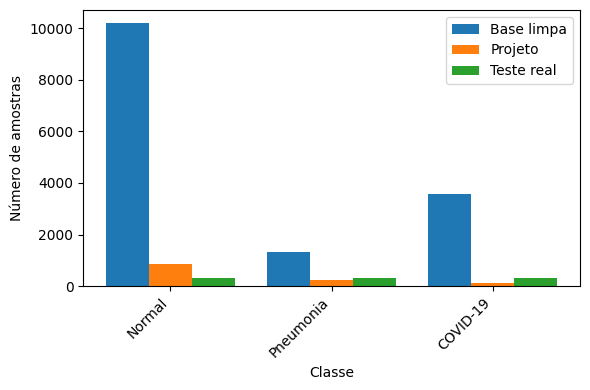

In [ ]:
from collections import Counter


with stopwatch.measure("download"):
    dataset_root = download_kaggle_dataset(DATASET_SLUG, DATA_DIR)
with stopwatch.measure("listagem e remoção de cópias"):
    files_found = count_xray_files(dataset_root)
    paths, labels = list_xray_images(dataset_root)
duplicates_removed = files_found - len(paths)
images_per_class = {CLASS_NAMES[label]: count for label, count in sorted(Counter(labels).items())}

project_indices = sample_per_class(labels, PROJECT_COUNTS, SEED)
test_indices = sample_per_class(
    labels, {label: TEST_PER_CLASS for label in PROJECT_COUNTS}, SEED, exclude=project_indices
)
with stopwatch.measure("leitura das imagens"):
    project_images = load_grayscale([paths[i] for i in project_indices], INPUT_SIZE)
    test_images = load_grayscale([paths[i] for i in test_indices], INPUT_SIZE)
project_labels = torch.tensor([labels[i] for i in project_indices])
test_labels = torch.tensor([labels[i] for i in test_indices])


def counts_by_name(values):
    """Counts how many times each class appears, keyed by class name."""
    return {CLASS_NAMES[label]: count for label, count in sorted(Counter(values).items())}


project_counts = counts_by_name(project_labels.tolist())
test_counts = counts_by_name(test_labels.tolist())
print("arquivos de imagem nas pastas das três classes:", files_found)
print("arquivos descartados (cópias exatas ou ilegíveis):", duplicates_removed)
print("imagens por classe depois da limpeza:", images_per_class)
print("conjunto do projeto:", project_counts)
print("conjunto de teste real:", test_counts)
print("imagens em comum entre projeto e teste:", len(set(project_indices) & set(test_indices)))
print("formato das imagens:", tuple(project_images.shape), project_images.dtype)

class_counts_figure = plot_class_counts(
    {"Base limpa": images_per_class, "Projeto": project_counts, "Teste real": test_counts},
    run.figures_dir / "class_counts.png",
)


## Parte A: o projeto que falhou, reproduzido

- Divisão 80/20 do conjunto do projeto, embaralhada e sem estratificação, seed 42
- ResNet-18 com pesos aleatórios, sem pré-treinamento
- SGD com taxa de aprendizado 0,01, sem momentum, 15 épocas, lotes de 32, sem augmentation
- O time reportou só a acurácia de treino e de validação. Aqui aparecem também a revocação por classe na validação deles, a revocação no teste real e quantas imagens de COVID-19 caíram na validação

epoch 1/15 train loss 0.6393 acc 0.7510 val loss 0.5514 acc 0.8167


epoch 2/15 train loss 0.4419 acc 0.8313 val loss 0.4436 acc 0.8625


epoch 3/15 train loss 0.3167 acc 0.8812 val loss 0.3523 acc 0.8750


epoch 4/15 train loss 0.2034 acc 0.9323 val loss 0.3422 acc 0.8833


epoch 5/15 train loss 0.1313 acc 0.9667 val loss 0.3054 acc 0.8958


...

epoch 12/15 train loss 0.0125 acc 1.0000 val loss 0.3242 acc 0.8875


epoch 13/15 train loss 0.0131 acc 0.9990 val loss 0.3223 acc 0.9000


epoch 14/15 train loss 0.0100 acc 1.0000 val loss 0.3232 acc 0.8917


epoch 15/15 train loss 0.0100 acc 1.0000 val loss 0.3250 acc 0.8958
projeto original: treino: 10.5 s


acurácia de treino na última época: 1.0
acurácia de validação na última época: 0.8958
imagens por classe na validação deles: {'Normal': 174, 'Pneumonia': 44, 'COVID-19': 22}
imagens de COVID-19 na validação deles: 22
acurácia de quem sempre responde a classe mais comum: 0.725
Normal: revocação na validação 0.9540, no teste real 0.9600
Pneumonia: revocação na validação 0.9091, no teste real 0.9600
COVID-19: revocação na validação 0.4091, no teste real 0.3733
acurácia no teste real: 0.7644


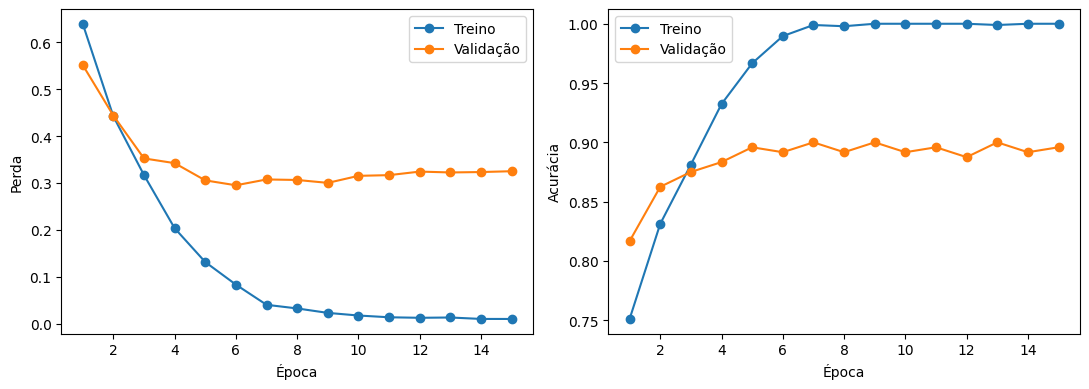

In [ ]:
def make_batches(images, targets, batch_size, seed, shuffle=False, augment=False, output_size=None):
    """Builds in-memory batches of X-rays, optionally shuffled and augmented."""
    return XrayBatches(
        images,
        targets,
        batch_size,
        output_size=output_size,
        augment=augment,
        shuffle=shuffle,
        max_shift=MAX_SHIFT_PIXELS,
        max_degrees=MAX_ROTATION_DEGREES,
        seed=seed,
        device=DEVICE,
    )


original_train, original_validation = train_test_split(
    list(range(len(project_indices))), test_size=VALIDATION_SHARE, shuffle=True, random_state=SEED
)
original_validation_labels = project_labels[original_validation]

seed_everything(SEED)
original_model = build_resnet18(len(CLASS_NAMES), pretrained=False).to(DEVICE)
original_optimizer = torch.optim.SGD(original_model.parameters(), lr=ORIGINAL_LEARNING_RATE)
with stopwatch.measure("projeto original: treino"):
    original_history = fit(
        original_model,
        make_batches(
            project_images[original_train], project_labels[original_train], ORIGINAL_BATCH_SIZE, SEED, shuffle=True
        ),
        make_batches(
            project_images[original_validation], original_validation_labels, ORIGINAL_BATCH_SIZE, SEED
        ),
        original_optimizer,
        epochs=ORIGINAL_EPOCHS,
        device=DEVICE,
    )
original_validation_report = evaluate(
    original_model,
    make_batches(project_images[original_validation], original_validation_labels, ORIGINAL_BATCH_SIZE, SEED),
    DEVICE,
    len(CLASS_NAMES),
)
original_test_report = evaluate(
    original_model,
    make_batches(test_images, test_labels, ORIGINAL_BATCH_SIZE, SEED),
    DEVICE,
    len(CLASS_NAMES),
)
original_validation_classes = class_report(original_validation_report["confusion"])
original_test_classes = class_report(original_test_report["confusion"])

validation_counts_original = counts_by_name(original_validation_labels.tolist())
majority_share = max(validation_counts_original.values()) / len(original_validation)
print("acurácia de treino na última época:", round(original_history["train_accuracy"][-1], 4))
print("acurácia de validação na última época:", round(original_history["val_accuracy"][-1], 4))
print("imagens por classe na validação deles:", validation_counts_original)
print("imagens de COVID-19 na validação deles:", validation_counts_original.get("COVID-19", 0))
print("acurácia de quem sempre responde a classe mais comum:", round(majority_share, 4))
for name, on_validation, on_test in zip(CLASS_NAMES, original_validation_classes, original_test_classes):
    print(f"{name}: revocação na validação {on_validation['recall']:.4f}, no teste real {on_test['recall']:.4f}")
print("acurácia no teste real:", round(original_test_report["accuracy"], 4))

original_history_figure = plot_history(original_history, run.figures_dir / "original_history.png")


## Parte B: o protocolo do resto do notebook

- Divisão 80/20 do conjunto do projeto, agora estratificada: cada classe mantém a mesma proporção no treino e na validação
- O conjunto de teste real fica separado e é usado só para medir
- A GAN só vê o treino. Validação e teste nunca recebem imagem gerada

In [ ]:
train_positions, validation_positions = train_test_split(
    list(range(len(project_indices))),
    test_size=VALIDATION_SHARE,
    stratify=project_labels.tolist(),
    random_state=SEED,
)
train_images = project_images[train_positions]
train_labels = project_labels[train_positions]
validation_images = project_images[validation_positions]
validation_labels = project_labels[validation_positions]

train_counts = counts_by_name(train_labels.tolist())
validation_counts = counts_by_name(validation_labels.tolist())
print("treino (só imagens reais):", train_counts)
print("validação (só imagens reais):", validation_counts)
print("teste (só imagens reais):", test_counts)
print("imagens em comum entre treino e validação:", len(set(train_positions) & set(validation_positions)))
print("imagens em comum entre treino e teste:", len(set(project_indices[i] for i in train_positions) & set(test_indices)))
print("imagens que a GAN vai ver:", train_images.shape[0], "(todas do treino)")


treino (só imagens reais): {'Normal': 672, 'Pneumonia': 192, 'COVID-19': 96}
validação (só imagens reais): {'Normal': 168, 'Pneumonia': 48, 'COVID-19': 24}
teste (só imagens reais): {'Normal': 300, 'Pneumonia': 300, 'COVID-19': 300}
imagens em comum entre treino e validação: 0
imagens em comum entre treino e teste: 0
imagens que a GAN vai ver: 960 (todas do treino)


## Parte C: a GAN condicional, duas versões com três seeds cada

Uma GAN tem dois modelos que treinam um contra o outro. O gerador cria imagens a partir de ruído e de um rótulo de classe. O discriminador tenta separar imagens reais das geradas. Aqui as duas redes recebem o rótulo, então o gerador sabe qual classe desenhar. Treino só com as imagens de treino, nas três classes, em 64x64.

- **Versão 1 (a base):** perda de entropia cruzada binária (BCE), discriminador com batch normalization, as duas taxas de aprendizado em 2e-4, lotes sorteados como vêm dos dados
- **Versão 2 (a mitigação, lotes balanceados por classe):** a mesma rede, a mesma perda e as mesmas taxas da versão 1. A única mudança é o sorteio dos lotes. O treino tem 672 imagens Normal, 192 Pneumonia e 96 COVID-19, e os rótulos das imagens falsas seguem os rótulos do lote real, então só cerca de 10% das atualizações do gerador são de COVID-19. Na versão 2 cada índice é sorteado com reposição, com probabilidade inversa à frequência da classe, e cada classe fica com a mesma parcela esperada dos lotes. O número de lotes por época não muda
- **Três seeds por versão (42, 43 e 44).** Para cada seed, a inicialização das redes e o treino usam essa seed. Uma só execução por versão não separa o efeito da versão do acaso da GPU, então o que vale é a média e o desvio padrão entre as seeds
- Mesmo número de épocas, mesmo tamanho de lote (64) e mesmos 32 canais base nas duas versões
- A diversidade é a diferença média de pixels entre pares de imagens da mesma classe. Perto de zero indica colapso de modo. A razão é a diversidade gerada na última décima parte das épocas dividida pela diversidade das imagens reais de treino da classe. Razão abaixo de 0,5 marca colapso. A diversidade lida na época 1 não é confiável e não é interpretada
- Balancear pode aumentar a diversidade só porque o gerador produz ruído. Por isso a distância das imagens geradas de COVID-19 até as imagens reais de treino também é medida, para cada versão e seed, e comparada com a distância das imagens reais de validação

**Conta das épocas.** O tempo total fica em cerca de 24 minutos na T4. Medido na execução anterior: versão 1 gasta cerca de 0,68 s por época, a versão 2 tem o mesmo custo por época (mesma rede e mesmo número de lotes, usado 0,68 s), e o resto do notebook (download, leitura, projeto original, três braços) cerca de 4,5 minutos (270 s). Com três seeds, cada época custa 3 x (0,68 + 0,68) = 4,08 s. Sobram 1.440 - 270 = 1.170 s para a GAN, o que dá 1.170 / 4,08 = 286,8 épocas. O maior valor inteiro entre 200 e 300 que cabe é 286 épocas, usado nas duas versões.

**Outras tentativas.** Em execuções anteriores deste notebook duas outras mitigações foram testadas com uma seed por versão, e uma terceira com três seeds e 240 épocas. Os números estão no relatório e no arquivo de resultados (`earlier_executions`). Não são resultados desta execução.

- Normalização espectral com perda hinge e taxas de aprendizado diferentes: colapsou em todas as execuções
- Aumento diferenciável (translação e brilho aleatórios antes do discriminador): ficou pior que a versão 1
- WGAN-GP (perda de Wasserstein com penalidade de gradiente): com três seeds, razão média de diversidade de COVID-19 de 0,485 com desvio padrão de 0,370 contra 0,591 e 0,051 da versão 1, e uma das três seeds colapsou durante todo o treino

treino da GAN v1, seed 42: 187.2 s
v1, seed 42: 0.65 s por época


treino da GAN v1, seed 43: 189.0 s
v1, seed 43: 0.66 s por época


treino da GAN v1, seed 44: 189.1 s
v1, seed 44: 0.66 s por época


treino da GAN v2, seed 42: 189.0 s
v2, seed 42: 0.66 s por época


treino da GAN v2, seed 43: 188.8 s
v2, seed 43: 0.66 s por época


treino da GAN v2, seed 44: 188.8 s
v2, seed 44: 0.66 s por época


diversidade das imagens reais de treino: {'Normal': 0.1966, 'Pneumonia': 0.1596, 'COVID-19': 0.2194}
v1 seed 42, razão para a diversidade real: {'Normal': 0.998, 'Pneumonia': 0.771, 'COVID-19': 0.498}
v1 seed 42, perda do discriminador no fim: 0.436, perda do gerador no fim: 3.077, discriminador vencendo: False, perda não finita: False
v1 seed 43, razão para a diversidade real: {'Normal': 0.992, 'Pneumonia': 0.905, 'COVID-19': 0.535}
v1 seed 43, perda do discriminador no fim: 0.523, perda do gerador no fim: 2.844, discriminador vencendo: False, perda não finita: False
v1 seed 44, razão para a diversidade real: {'Normal': 1.009, 'Pneumonia': 0.791, 'COVID-19': 0.698}
v1 seed 44, perda do discriminador no fim: 0.531, perda do gerador no fim: 2.842, discriminador vencendo: False, perda não finita: False
v1 Normal: razão média 0.999, desvio padrão 0.009, seeds com colapso 0 de 3
v1 Pneumonia: razão média 0.822, desvio padrão 0.072, seeds com colapso 0 de 3
v1 COVID-19: razão média 0.577, d

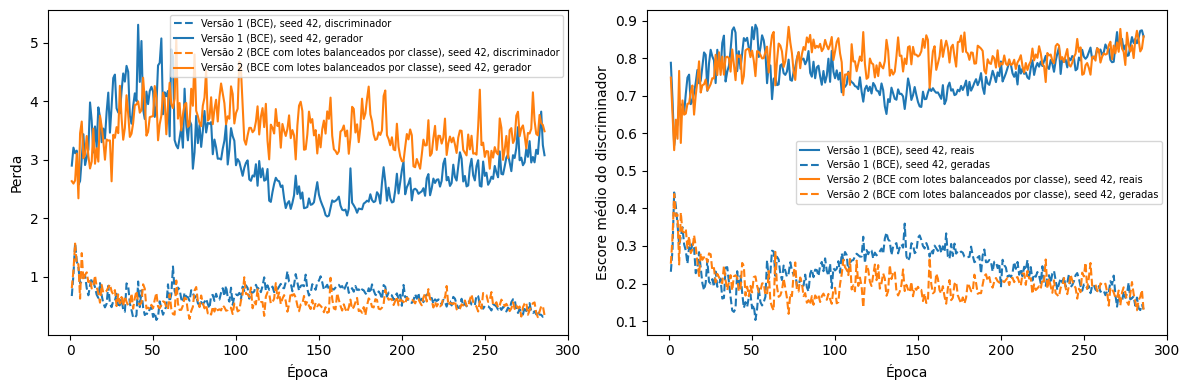

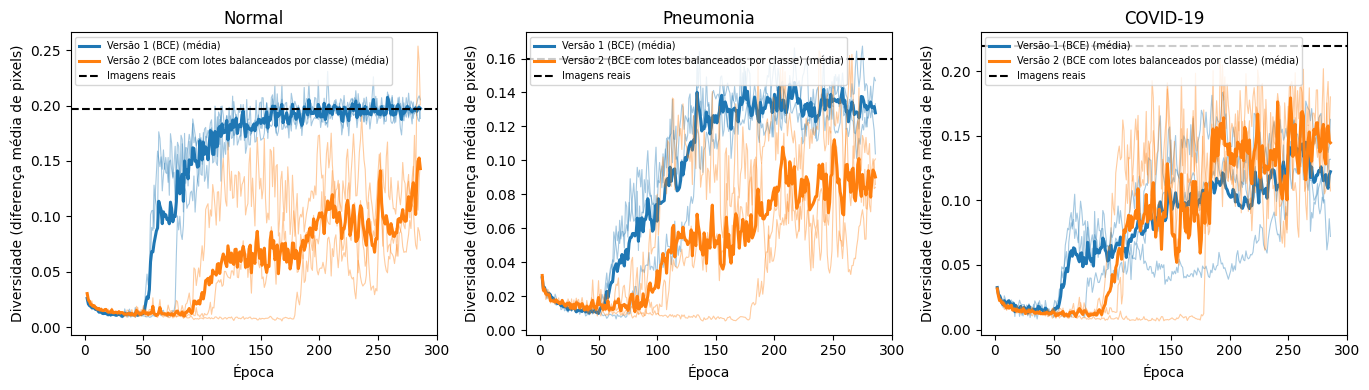

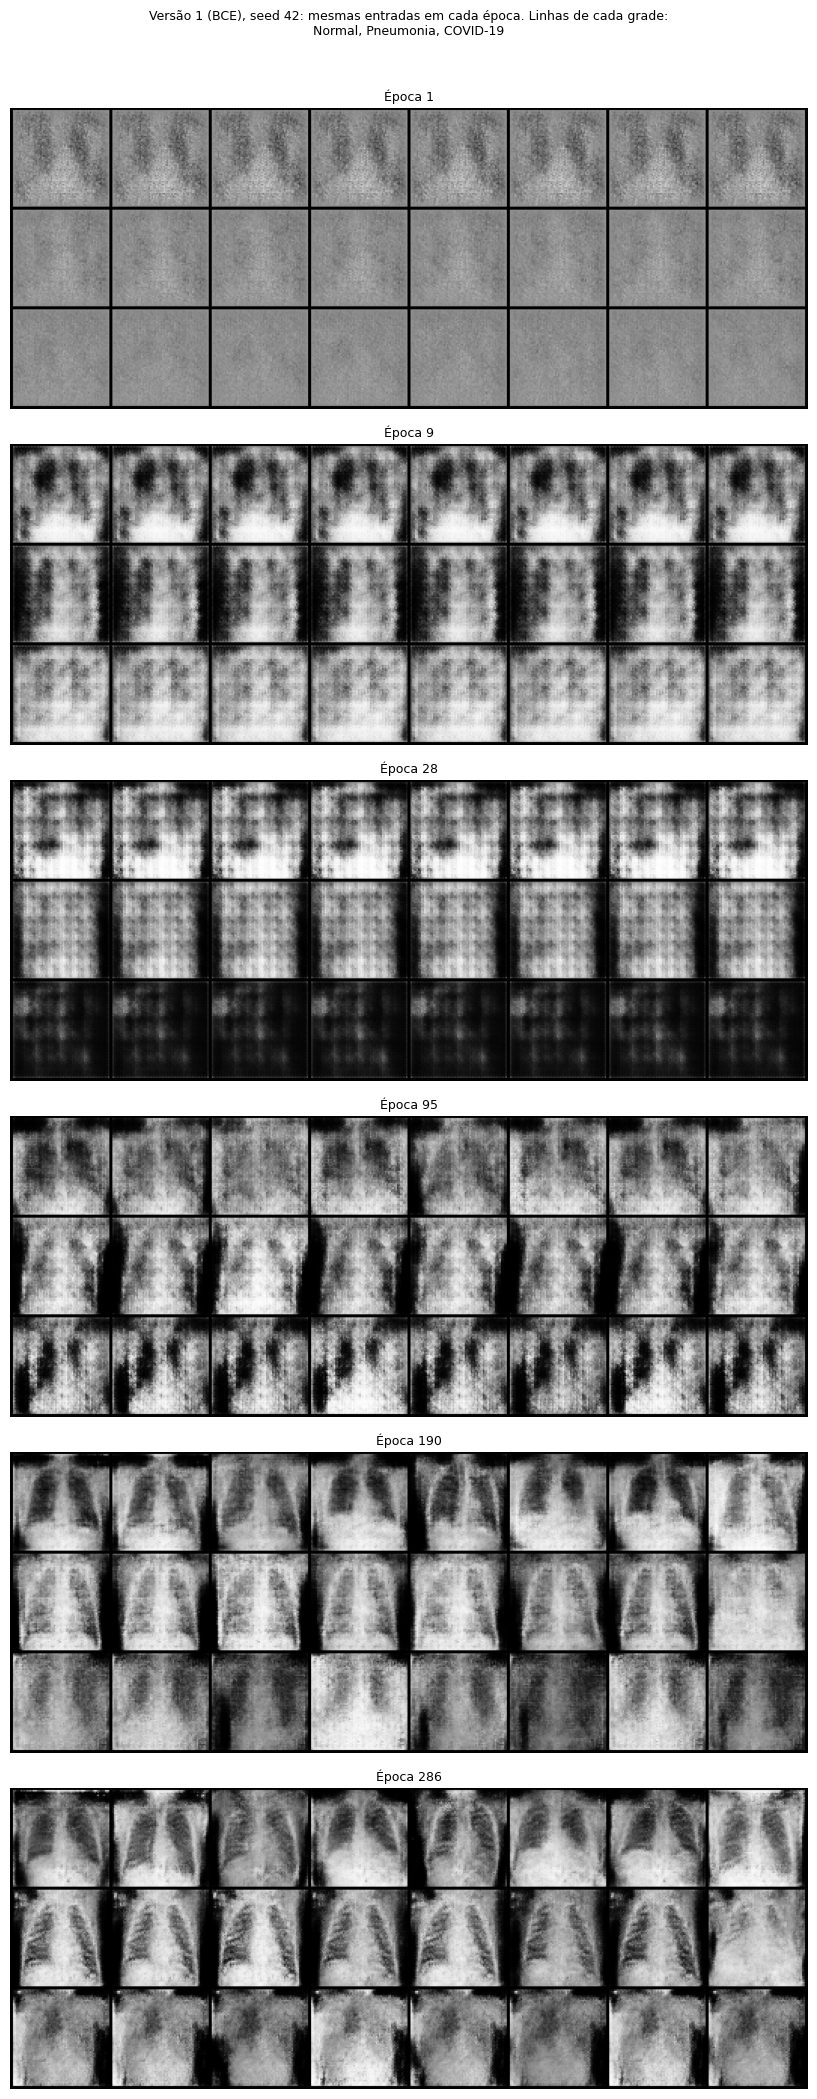

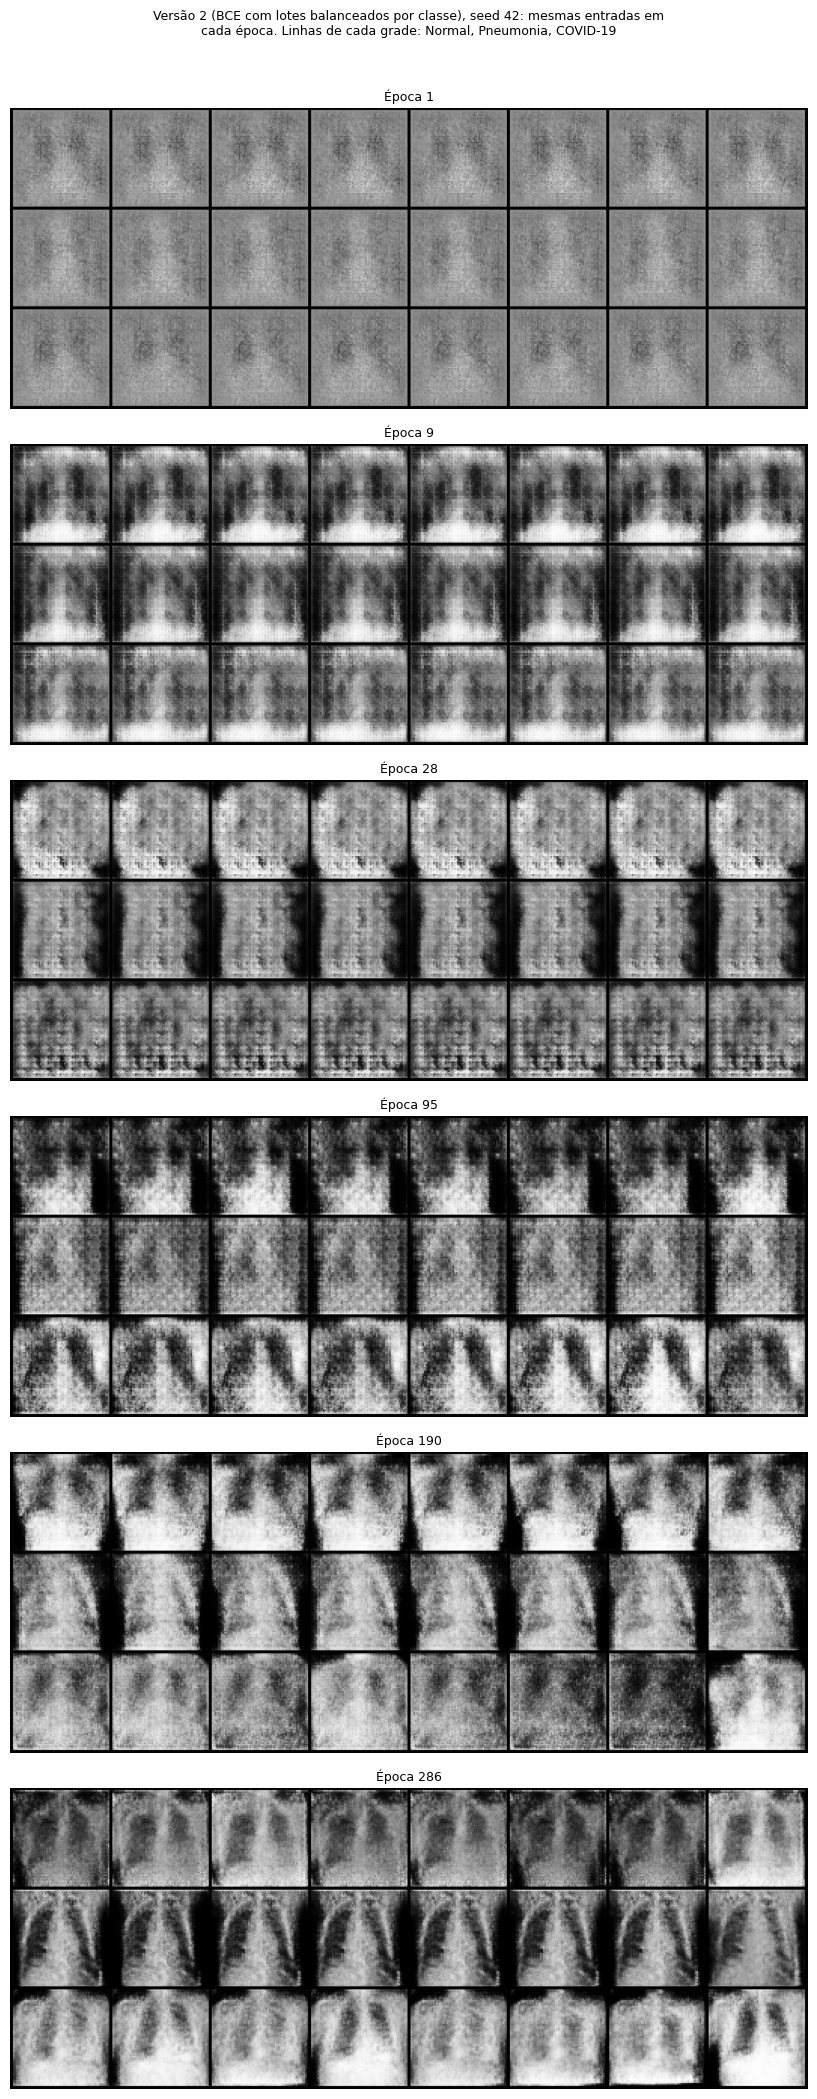

In [ ]:
snapshot_epochs = sorted(
    {1, max(1, GAN_EPOCHS // 30), max(1, GAN_EPOCHS // 10), GAN_EPOCHS // 3, 2 * GAN_EPOCHS // 3, GAN_EPOCHS}
)
generators = {key: {} for key in GAN_VERSIONS}
histories = {key: {} for key in GAN_VERSIONS}

for key, settings in GAN_VERSIONS.items():
    for gan_seed in GAN_SEEDS:
        step = f"treino da GAN {key}, seed {gan_seed}"
        with stopwatch.measure(step):
            generators[key][gan_seed], histories[key][gan_seed] = train_gan_version(
                settings,
                train_images,
                train_labels,
                gan_seed,
                epochs=GAN_EPOCHS,
                batch_size=GAN_BATCH_SIZE,
                base_channels=GAN_BASE_CHANNELS,
                device=DEVICE,
                snapshot_epochs=snapshot_epochs,
                num_classes=len(CLASS_NAMES),
            )
        print(f"{key}, seed {gan_seed}: {stopwatch.seconds[step] / GAN_EPOCHS:.2f} s por época")

real_diversity = {
    label: pairwise_diversity(train_images[train_labels == label]) for label in range(len(CLASS_NAMES))
}
diagnoses = {
    key: {gan_seed: diagnose_gan(histories[key][gan_seed], real_diversity) for gan_seed in GAN_SEEDS}
    for key in GAN_VERSIONS
}
summaries = {key: summarise_diagnoses([diagnoses[key][gan_seed] for gan_seed in GAN_SEEDS]) for key in GAN_VERSIONS}

print("diversidade das imagens reais de treino:", {CLASS_NAMES[i]: round(v, 4) for i, v in real_diversity.items()})
for key in GAN_VERSIONS:
    for gan_seed, found in diagnoses[key].items():
        print(key, f"seed {gan_seed}, razão para a diversidade real:", {CLASS_NAMES[i]: round(v, 3) for i, v in found["diversity_ratio"].items()})
        print(
            key,
            f"seed {gan_seed}, perda do discriminador no fim: {found['discriminator_loss_final']:.3f}, "
            f"perda do gerador no fim: {found['generator_loss_final']:.3f}, "
            f"discriminador vencendo: {found['discriminator_wins']}, perda não finita: {found['non_finite_loss']}",
        )
    found = summaries[key]
    for label, name in enumerate(CLASS_NAMES):
        print(
            key,
            f"{name}: razão média {found['diversity_ratio_mean'][label]:.3f}, "
            f"desvio padrão {found['diversity_ratio_std'][label]:.3f}, "
            f"seeds com colapso {found['collapsed_seeds'][label]} de {found['seeds']}",
        )
    print(key, "alguma seed com perda não finita:", found["any_non_finite_loss"])

version_names = {key: settings["name"] for key, settings in GAN_VERSIONS.items()}
figure_seed = GAN_SEEDS[0]
curves_figure = plot_gan_curves(
    {f"{version_names[key]}, seed {figure_seed}": histories[key][figure_seed] for key in GAN_VERSIONS},
    run.figures_dir / "gan_curves.png",
)
diversity_figure = plot_gan_diversity(
    {
        version_names[key]: [histories[key][gan_seed]["diversity"] for gan_seed in GAN_SEEDS]
        for key in GAN_VERSIONS
    },
    real_diversity,
    CLASS_NAMES,
    run.figures_dir / "gan_diversity.png",
)
snapshot_figures = {
    key: plot_gan_snapshots(
        histories[key][figure_seed]["snapshots"],
        run.figures_dir / f"gan_snapshots_{key}.png",
        f"{version_names[key]}, seed {figure_seed}: mesmas entradas em cada época. Linhas de cada grade: {', '.join(CLASS_NAMES)}",
    )
    for key in GAN_VERSIONS
}


## Escolha da versão e memorização

- **Regra de escolha, fixada antes de ver os resultados e antes do experimento de revocação:** a versão com a maior razão média de diversidade na classe COVID-19, em média entre as três seeds. Se a diferença entre as médias for menor que o desvio padrão entre seeds, a regra ainda escolhe uma versão, e o relatório diz que a diferença está dentro da variação
- **Memorização e qualidade:** para cada imagem sintética de COVID-19, a distância média de pixels até a imagem real de COVID-19 mais próxima no treino. É calculada para cada versão e cada seed. Para ter uma régua, a mesma conta é feita com as imagens reais de COVID-19 da validação contra as do treino. Se as sintéticas estivessem coladas no treino, a distância delas seria bem menor que a das reais de validação. Se estiverem bem mais longe que as reais de validação, são imagens de pior qualidade, e a diversidade maior não é um ganho
- **Braço 2 da Parte D:** o classificador da seed i usa as imagens sintéticas geradas pela GAN da seed i da versão escolhida

regra: versão com a maior razão média de diversidade na classe COVID-19 entre as três seeds
Versão 1 (BCE): razão média 0.577, desvio padrão 0.106
Versão 2 (BCE com lotes balanceados por classe): razão média 0.660, desvio padrão 0.021
versão escolhida: v2 - Versão 2 (BCE com lotes balanceados por classe)


sintéticas de COVID-19 (três seeds) até o treino: {'count': 1728, 'mean': 0.11967922002077103, 'median': 0.11557183414697647, 'minimum': 0.08246485888957977}
validação real de COVID-19 até o treino: {'count': 24, 'mean': 0.10494676232337952, 'median': 0.09938675910234451, 'minimum': 0.07179507613182068}
como ler: distância das geradas muito maior que a das reais de validação indica imagens de pior qualidade, não mais diversidade; distância muito menor indica cópia
Versão 1 (BCE) distância média até o treino por seed: {42: 0.1427, 43: 0.1318, 44: 0.1073} | reais de validação: 0.1049
Versão 2 (BCE com lotes balanceados por classe) distância média até o treino por seed: {42: 0.113, 43: 0.1079, 44: 0.1381} | reais de validação: 0.1049
parte das sintéticas mais perto do treino que a real mais próxima: 0.0


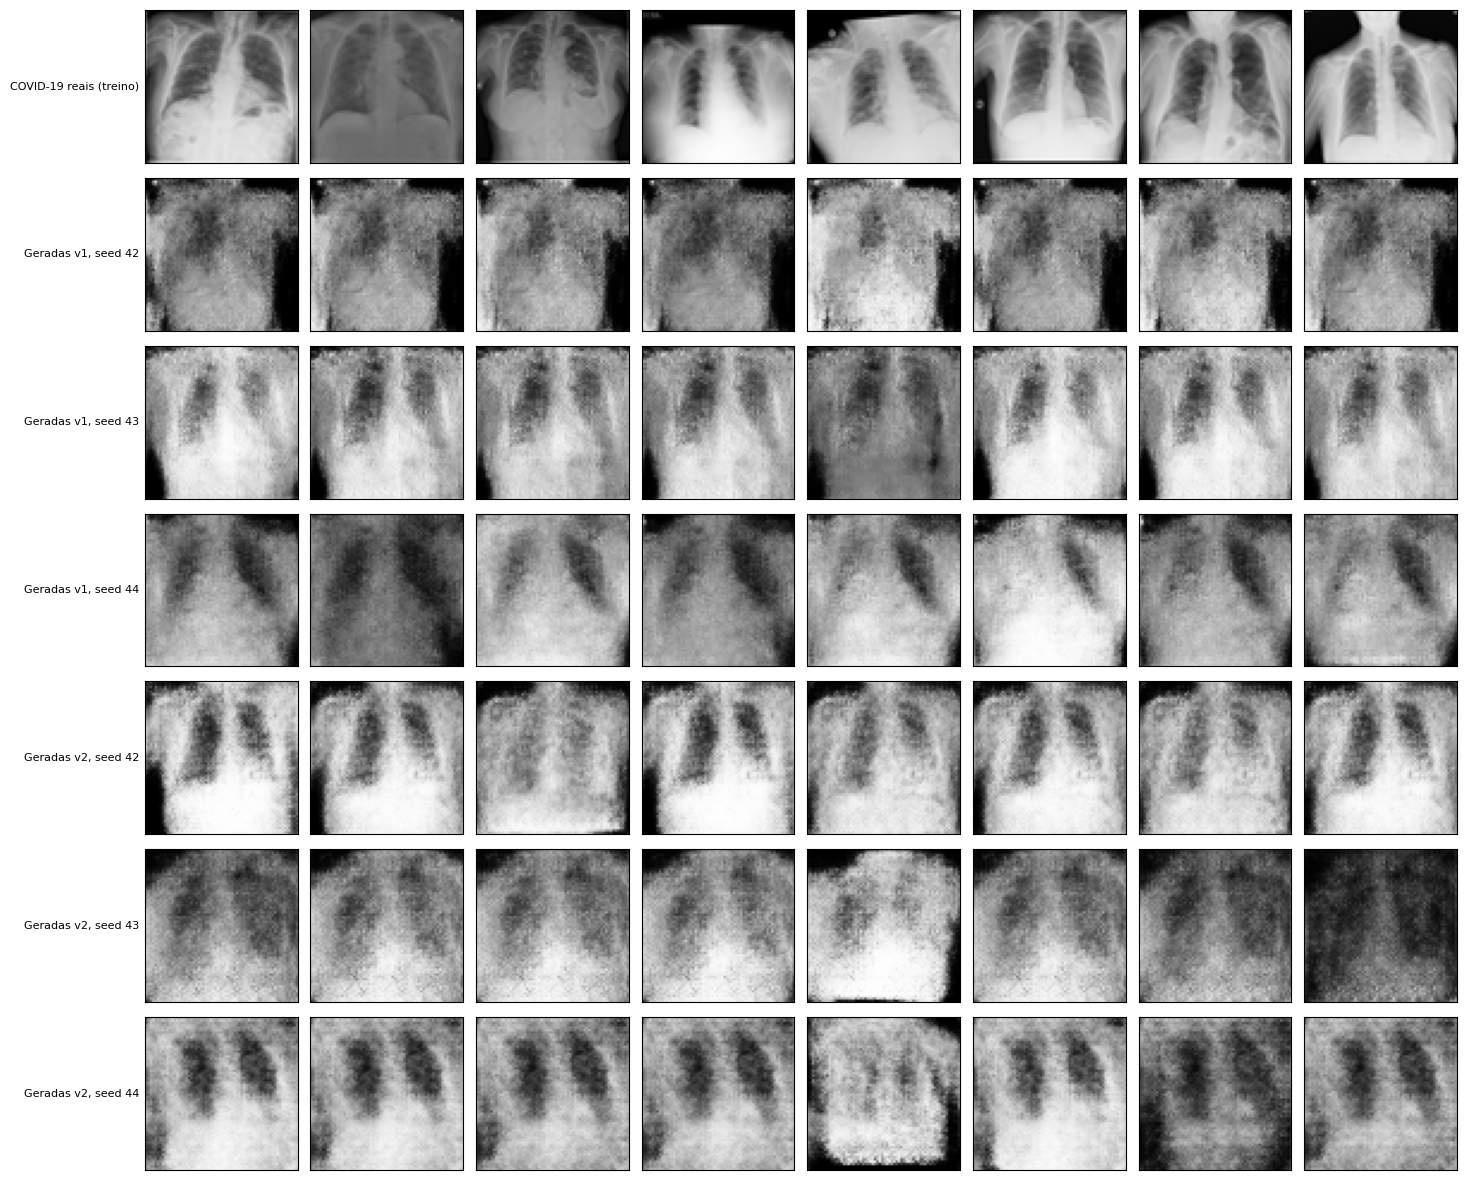

In [ ]:
CHOICE_RULE = "versão com a maior razão média de diversidade na classe COVID-19 entre as três seeds"
choice = choose_by_mean_ratio(summaries, COVID_LABEL)
chosen_version = choice["chosen"]
print("regra:", CHOICE_RULE)
for key, value in choice["means"].items():
    print(f"{version_names[key]}: razão média {value:.3f}, desvio padrão {summaries[key]['diversity_ratio_std'][COVID_LABEL]:.3f}")
print("versão escolhida:", chosen_version, "-", version_names[chosen_version])

synthetic_count = train_counts["Normal"] - train_counts["COVID-19"]
synthetic_by_version = {
    key: {
        gan_seed: generate(
            generators[key][gan_seed], torch.full((synthetic_count,), COVID_LABEL), DEVICE, gan_seed
        )
        for gan_seed in GAN_SEEDS
    }
    for key in GAN_VERSIONS
}
synthetic_by_seed = synthetic_by_version[chosen_version]
synthetic_covid = torch.cat(list(synthetic_by_seed.values()))
train_covid = train_images[train_labels == COVID_LABEL]
validation_covid = validation_images[validation_labels == COVID_LABEL]
generated_distance = nearest_real_distance(synthetic_covid, train_covid)
real_distance = nearest_real_distance(validation_covid, train_covid)


def describe_distances(distances):
    """Summarises nearest-image distances by mean, median and minimum."""
    return {
        "count": int(distances.numel()),
        "mean": float(distances.mean()),
        "median": float(distances.median()),
        "minimum": float(distances.min()),
    }


distance_by_version_seed = {
    key: {
        gan_seed: float(nearest_real_distance(images, train_covid).mean())
        for gan_seed, images in per_seed.items()
    }
    for key, per_seed in synthetic_by_version.items()
}
memorisation = {
    "chosen_version": chosen_version,
    "mean_distance_by_version_and_seed": distance_by_version_seed,
    "seeds": list(GAN_SEEDS),
    "generated_to_train": describe_distances(generated_distance),
    "validation_to_train": describe_distances(real_distance),
    "generated_below_real_minimum": float((generated_distance < real_distance.min()).float().mean()),
}
print("sintéticas de COVID-19 (três seeds) até o treino:", memorisation["generated_to_train"])
print("validação real de COVID-19 até o treino:", memorisation["validation_to_train"])
print("como ler: distância das geradas muito maior que a das reais de validação indica imagens de pior qualidade, não mais diversidade; distância muito menor indica cópia")
for key, per_seed in distance_by_version_seed.items():
    print(version_names[key], "distância média até o treino por seed:", {gan_seed: round(value, 4) for gan_seed, value in per_seed.items()}, "| reais de validação:", round(memorisation["validation_to_train"]["mean"], 4))
print("parte das sintéticas mais perto do treino que a real mais próxima:", round(memorisation["generated_below_real_minimum"], 4))

sample_count = 8
samples_figure = plot_sample_rows(
    {
        "COVID-19 reais (treino)": train_covid[:sample_count],
        **{
            f"Geradas {key}, seed {gan_seed}": images[:sample_count]
            for key, per_seed in synthetic_by_version.items()
            for gan_seed, images in per_seed.items()
        },
    },
    run.figures_dir / "real_vs_synthetic.png",
)


## Parte D: as imagens sintéticas aumentam a revocação de COVID-19?

- Classificador: `resnet18` do torchvision com pesos da ImageNet, todas as camadas treinadas
- Entrada: 64x64 em tons de cinza, repetida em três canais, ampliada para 128 e normalizada com a média e o desvio padrão da ImageNet
- Adam com taxa de aprendizado 1e-4, 10 épocas, lotes de 32
- Augmentation leve e igual nos três braços: pequena translação e rotação de até 7 graus. Sem espelhamento horizontal, porque esquerda e direita importam em uma radiografia de tórax
- **Braço 1:** só imagens reais de treino
- **Braço 2:** imagens reais mais imagens sintéticas de COVID-19 da versão escolhida da GAN, o bastante para igualar a contagem de Normal. O classificador da seed i recebe as imagens da GAN de seed i
- **Braço 3:** só imagens reais, com perda ponderada pelo inverso da frequência das classes. É a alternativa simples, sem GAN
- Três seeds por braço. A avaliação é no teste real de 300 imagens por classe. Aparecem média e desvio padrão entre as seeds

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


  0%|          | 0.00/44.7M [00:00<?, ?B/s]

 39%|███▊      | 17.2M/44.7M [00:00<00:00, 181MB/s]

 88%|████████▊ | 39.2M/44.7M [00:00<00:00, 210MB/s]

100%|██████████| 44.7M/44.7M [00:00<00:00, 207MB/s]

...

epoch 7/10 train loss 0.0419 acc 0.9875 val loss 0.2872 acc 0.9500


epoch 8/10 train loss 0.0492 acc 0.9812 val loss 0.2437 acc 0.9375


epoch 9/10 train loss 0.0537 acc 0.9760 val loss 0.2366 acc 0.9292


epoch 10/10 train loss 0.0484 acc 0.9792 val loss 0.1608 acc 0.9500


braço: Reais com pesos de classe: 39.3 s
Só reais: imagens de treino {'Normal': 672, 'Pneumonia': 192, 'COVID-19': 96}
  acurácia no teste: média 0.8074, desvio 0.0545
  Normal, recall: média 0.9956, desvio 0.0038
  Pneumonia, recall: média 0.8433, desvio 0.0731
  COVID-19, recall: média 0.5833, desvio 0.1601
  Normal, precision: média 0.6486, desvio 0.0632
  Pneumonia, precision: média 0.9729, desvio 0.0209
  COVID-19, precision: média 0.9950, desvio 0.0045
  Normal, f1: média 0.7841, desvio 0.0460
  Pneumonia, f1: média 0.9020, desvio 0.0360
  COVID-19, f1: média 0.7269, desvio 0.1217
Reais e sintéticas: imagens de treino {'Normal': 672, 'Pneumonia': 192, 'COVID-19': 672}
  acurácia no teste: média 0.8530, desvio 0.0290
  Normal, recall: média 0.9967, desvio 0.0033
  Pneumonia, recall: média 0.8989, desvio 0.0627
  COVID-19, recall: média 0.6633, desvio 0.0437
  Normal, precision: média 0.7039, desvio 0.0413
  Pneumonia, precision: média 0.9831, desvio 0.0105
  COVID-19, precision: m

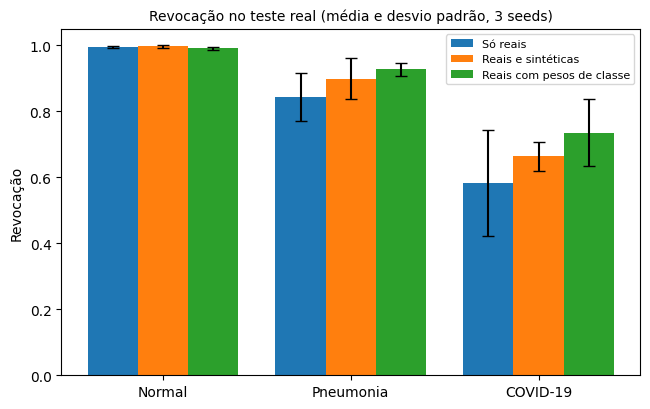

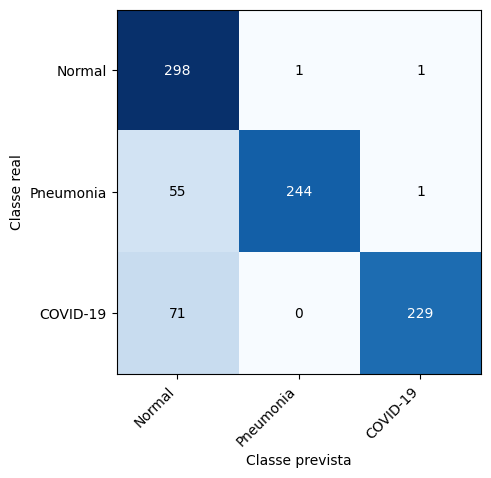

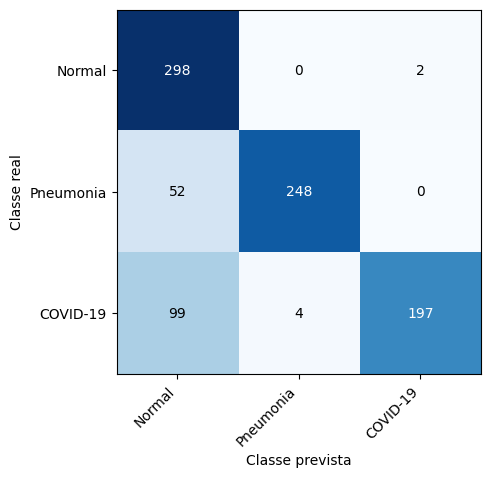

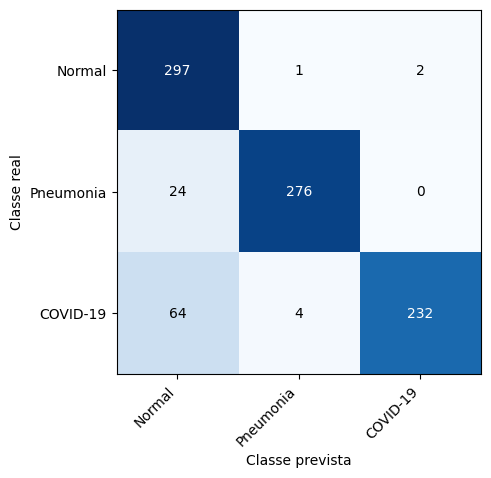

In [ ]:
ARMS = {
    "Só reais": {"synthetic": False, "weighted": False},
    "Reais e sintéticas": {"synthetic": True, "weighted": False},
    "Reais com pesos de classe": {"synthetic": False, "weighted": True},
}


def train_arm(settings, seed):
    """Trains and evaluates one classifier of an arm, and returns its history and test results."""
    seed_everything(seed)
    images, targets = train_images, train_labels.tolist()
    if settings["synthetic"]:
        images, targets = mix_synthetic(train_images, targets, synthetic_by_seed[seed], COVID_LABEL)
    weights = inverse_frequency_weights(targets, len(CLASS_NAMES)) if settings["weighted"] else None
    model = build_resnet18(len(CLASS_NAMES), pretrained=True).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=CLASSIFIER_LEARNING_RATE)
    history = fit(
        model,
        make_batches(
            images, targets, CLASSIFIER_BATCH_SIZE, seed, shuffle=True, augment=True, output_size=CLASSIFIER_INPUT_SIZE
        ),
        make_batches(
            validation_images, validation_labels, CLASSIFIER_BATCH_SIZE, seed, output_size=CLASSIFIER_INPUT_SIZE
        ),
        optimizer,
        epochs=CLASSIFIER_EPOCHS,
        device=DEVICE,
        class_weights=weights,
    )
    evaluation = evaluate(
        model,
        make_batches(test_images, test_labels, CLASSIFIER_BATCH_SIZE, seed, output_size=CLASSIFIER_INPUT_SIZE),
        DEVICE,
        len(CLASS_NAMES),
    )
    return {
        "seed": seed,
        "training_images": int(images.shape[0]),
        "training_counts": counts_by_name(list(targets)),
        "history": history,
        "accuracy": evaluation["accuracy"],
        "confusion": evaluation["confusion"],
        "report": class_report(evaluation["confusion"]),
    }


arm_runs = {}
for arm, settings in ARMS.items():
    with stopwatch.measure(f"braço: {arm}"):
        arm_runs[arm] = [train_arm(settings, seed) for seed in CLASSIFIER_SEEDS]

arm_summaries = {
    arm: {
        metric: summarise_runs([result["report"] for result in results], metric)
        for metric in ("recall", "precision", "f1")
    }
    for arm, results in arm_runs.items()
}
for arm, results in arm_runs.items():
    print(f"{arm}: imagens de treino {results[0]['training_counts']}")
    accuracies = torch.tensor([result["accuracy"] for result in results])
    print(f"  acurácia no teste: média {accuracies.mean():.4f}, desvio {accuracies.std():.4f}")
    for metric in ("recall", "precision", "f1"):
        for name, row in zip(CLASS_NAMES, arm_summaries[arm][metric]):
            print(f"  {name}, {metric}: média {row['mean']:.4f}, desvio {row['std']:.4f}")
print("teste real por classe:", test_counts)

recall_figure = plot_arm_metric(
    {arm: arm_summaries[arm]["recall"] for arm in ARMS},
    CLASS_NAMES,
    "Revocação no teste real (média e desvio padrão, 3 seeds)",
    run.figures_dir / "recall_arms.png",
)
confusion_figures = {
    arm: plot_confusion(
        arm_runs[arm][0]["confusion"], CLASS_NAMES, run.figures_dir / f"confusion_arm{number}.png"
    )
    for number, arm in enumerate(ARMS, start=1)
}


## Leitura dos resultados

A leitura dos resultados está no relatório.

In [ ]:
gan_metrics = {
    key: {
        "name": settings["name"],
        "hyperparameters": {
            **settings,
            "epochs": GAN_EPOCHS,
            "batch_size": GAN_BATCH_SIZE,
            "base_channels": GAN_BASE_CHANNELS,
            "seeds": list(GAN_SEEDS),
        },
        "histories": {
            gan_seed: {name: values for name, values in histories[key][gan_seed].items() if name != "snapshots"}
            for gan_seed in GAN_SEEDS
        },
        "diagnoses": diagnoses[key],
        "summary": summaries[key],
        "seconds_per_epoch": round(
            sum(stopwatch.seconds[f"treino da GAN {key}, seed {gan_seed}"] for gan_seed in GAN_SEEDS)
            / (GAN_EPOCHS * len(GAN_SEEDS)),
            3,
        ),
    }
    for key, settings in GAN_VERSIONS.items()
}
metrics = {
    "class_names": CLASS_NAMES,
    "files_found": files_found,
    "duplicates_removed": duplicates_removed,
    "images_per_class": images_per_class,
    "project_counts": project_counts,
    "test_counts": test_counts,
    "train_counts": train_counts,
    "validation_counts": validation_counts,
    "original_project": {
        "train_accuracy": original_history["train_accuracy"][-1],
        "validation_accuracy": original_history["val_accuracy"][-1],
        "test_accuracy": original_test_report["accuracy"],
        "covid_in_validation": validation_counts_original.get("COVID-19", 0),
        "validation_counts": validation_counts_original,
        "majority_class_accuracy": majority_share,
        "recall_validation": dict(zip(CLASS_NAMES, [row["recall"] for row in original_validation_classes])),
        "recall_test": dict(zip(CLASS_NAMES, [row["recall"] for row in original_test_classes])),
        "confusion_validation": original_validation_report["confusion"],
        "confusion_test": original_test_report["confusion"],
        "history": original_history,
    },
    "gan": gan_metrics,
    "real_diversity": real_diversity,
    "chosen_version": {
        "version": chosen_version,
        "rule": CHOICE_RULE,
        "class": CLASS_NAMES[COVID_LABEL],
        "mean_ratio": choice["means"],
        "std_ratio": {key: summaries[key]["diversity_ratio_std"][COVID_LABEL] for key in GAN_VERSIONS},
    },
    "earlier_executions": EARLIER_EXECUTIONS,
    "memorisation": memorisation,
    "arms": {
        arm: {"runs": arm_runs[arm], "summary": arm_summaries[arm]} for arm in ARMS
    },
    "hyperparameters": {
        "seed": SEED,
        "input_size": INPUT_SIZE,
        "project_counts": PROJECT_COUNTS,
        "test_per_class": TEST_PER_CLASS,
        "validation_share": VALIDATION_SHARE,
        "original": {
            "model": "resnet18, random weights",
            "optimizer": "SGD, no momentum",
            "learning_rate": ORIGINAL_LEARNING_RATE,
            "epochs": ORIGINAL_EPOCHS,
            "batch_size": ORIGINAL_BATCH_SIZE,
            "split": "plain shuffle, no stratification",
        },
        "classifier": {
            "model": "resnet18 IMAGENET1K_V1, all layers trained",
            "optimizer": "Adam",
            "learning_rate": CLASSIFIER_LEARNING_RATE,
            "epochs": CLASSIFIER_EPOCHS,
            "batch_size": CLASSIFIER_BATCH_SIZE,
            "input_size": CLASSIFIER_INPUT_SIZE,
            "seeds": list(CLASSIFIER_SEEDS),
            "augmentation": f"shift up to {MAX_SHIFT_PIXELS} px, rotation up to {MAX_ROTATION_DEGREES} degrees, no flip",
            "synthetic_covid_per_seed": synthetic_count,
            "synthetic_pairing": "classifier seed i uses the GAN of seed i",
        },
    },
    "step_seconds": stopwatch.seconds,
}
archive = save_run(run, metrics)
saved = json.loads((run.output_dir / "metrics.json").read_text(encoding="utf-8"))
print("arquivo de saída:", archive)
print("tempo total (s):", saved["runtime_seconds"])
print("pico de memória de GPU (MB):", saved["peak_gpu_memory_mb"])
print("pico de memória RAM (MB):", saved["peak_ram_mb"])


arquivo de saída: outputs_a4.zip
tempo total (s): 1392.9
pico de memória de GPU (MB): 656.5
pico de memória RAM (MB): 2151.1
